# Resumen departamental con NASA POWER · pandas vs Polars con memoria acotada

**Situación (ejercicio de clase del cuaderno 04):** una entidad debe generar **semanalmente** el
mismo resumen departamental. Dispone de un equipo con **8 GB de RAM**, el volumen podría
**duplicarse** durante el próximo año y el equipo analista conoce **pandas**, pero no **Polars**.

**Pregunta:** ¿qué motor, pandas o Polars, conviene para producir ese resumen cuando los datos
**no caben en la memoria** del equipo? La respuesta no puede basarse solo en el tiempo más bajo:
medimos **tiempo, CPU, memoria y disco** y sumamos el **costo de aprendizaje**.

**Datos:** tomamos como referencia `kit/data/raw/nasa.json`, una respuesta real de la API
NASA POWER (temperatura `T2M` y precipitación `PRECTOTCORR`, 31 días de enero de 2025, un
punto en Boyacá). Ese archivo pesa 1,5 KB, así que lo **replicamos K veces** hasta superar la
memoria del dispositivo. Cada réplica recibe como **etiqueta** un municipio real de DIVIPOLA
(`kit/data/raw/divipola.csv`) para que el resumen tenga departamentos.

> **Aviso:** los valores climáticos son los 31 días reales, idénticos en todas las réplicas.
> La ubicación es solo una etiqueta: **no interpretar el resultado como clima departamental**.
> El objetivo es comparar motores, no estudiar el clima.

**El dispositivo acotado:** este equipo tiene más RAM que el del enunciado, así que lo
**simulamos**. Cada medición corre en un proceso aparte con un **límite real de memoria**
(`MemoryMax` de systemd/cgroups, sin swap). Si el proceso lo supera, el sistema lo termina.

## Estrategia (la ruta de las diapositivas)

1. **Formular** la decisión y la hipótesis.
2. **Modelar** el costo: qué etapa debería explicar la diferencia.
3. **Diseñar** la medición: variables, controles y una prueba nueva (volumen 2×).
4. **Ejecutar y validar:** construir los datos, escribir las cuatro variantes, demostrar que
   pandas no puede leer todo de una vez, confirmar equivalencia y medir 10 veces cada variante.
   Decidir con **Friedman** y comparaciones **post-hoc**, como en `Read_pqrs.ipynb`.
5. **Interpretar y decidir** con una matriz de varios criterios.

Ejecutar las celdas en orden con el kernel del `.venv` del curso. La ejecución completa tarda
unos 15 minutos; casi todo ese tiempo lo consume pandas leyendo JSON.

# Paso 1 · Formular

**Decisión que debe tomar la entidad:** para el resumen departamental semanal, ¿mantener
pandas (leyendo por partes), migrar a Polars o adoptarlo de forma gradual, sabiendo que el
equipo tiene 8 GB y que el volumen puede duplicarse?

**Hipótesis:** Polars en modo *streaming* será más rápido, hará menos trabajo de CPU y usará
menos memoria que pandas por trozos. La mayor diferencia aparecerá al leer JSON, donde el costo
dominante es convertir texto en números. Cambiar a Parquet reducirá el costo de **ambos** motores.
pandas solo será viable si lee el archivo **por partes**.

- **Evidencia que apoyaría la hipótesis:** medianas menores de tiempo, CPU y memoria para
  Polars, con diferencias significativas (Friedman + post-hoc) que se mantienen con el doble
  de datos.
- **Evidencia que la refutaría:** que pandas por partes iguale a Polars en tiempo o memoria,
  que las diferencias no sean significativas, o que Polars supere el límite de memoria.

# Paso 2 · Modelar el costo

```text
leer bytes  →  decodificar texto  →  seleccionar  →  agrupar parcial  →  combinar  →  materializar
  disco             CPU               I/O + CPU          CPU              CPU           RAM
```

- **NDJSON (JSON Lines)** guarda una observación por línea y como texto. Aunque la consulta
  use 4 de 6 campos, hay que recorrer **cada línea completa** y convertir el texto en números.
- **pandas** convierte cada línea en un diccionario de Python y después en un `DataFrame`:
  muchos objetos pequeños y un solo núcleo de CPU. Si lee todo de una vez, esos objetos
  ocupan varias veces el tamaño del archivo.
- **Polars** tiene un lector escrito en Rust que usa varios hilos y solo materializa las columnas
  pedidas. En modo *streaming* procesa lotes y no necesita el archivo entero en memoria.
- **Parquet** guarda los datos por columnas, ya tipados y comprimidos: se leen solo 3 columnas
  y casi no hay texto que convertir.

**Predicción:** la etapa dominante será **decodificar texto (CPU)**, no leer el disco. En el
paso 4 lo contrastaremos con los CPU-segundos y los MB leídos del disco.

# Paso 3 · Diseñar la medición

| Tipo | En este cuaderno |
|---|---|
| Variable independiente | variante = motor (pandas, Polars) × formato (NDJSON, Parquet) |
| Variables dependientes | **tiempo:** segundos y filas/s · **CPU:** CPU-segundos, núcleos promedio y % de CPU · **memoria:** pico de memoria de trabajo y margen frente al límite · **disco:** MB leídos del dispositivo y MB que la consulta debe decodificar |
| Variables controladas | mismos datos, misma consulta, mismo **límite de memoria** para todas, **lectura en frío** en cada corrida, mismo equipo, orden aleatorio |
| Variables contextuales | hilos disponibles, versiones, sistema de archivos (btrfs con compresión), NVMe, procesos concurrentes |

**Contrato de equivalencia:** las cuatro variantes producen la misma tabla. La comparamos
contra una **tabla esperada** calculada a mano a partir de los 31 días reales.

**Frontera del reloj:** incluye leer, seleccionar, agrupar, combinar y materializar el resumen.
Excluye la generación de datos, la conversión a Parquet, el arranque del proceso, los `import`,
el vaciado de la caché, la escritura del resultado y la verificación.

**Por qué no basta el tiempo de pared:** Polars puede ser más rápido porque usa varios núcleos.
En un equipo compartido o con menos núcleos esa ventaja se reduce. Los **CPU-segundos** miden
el trabajo total, sin importar cuántos núcleos lo repartan.

- **Variable que mantenemos controlada:** el límite de memoria (`MEMORIA_MAX_MB`), igual para
  todas las variantes y menor que el archivo.
- **Prueba nueva necesaria:** repetir con el **doble de datos**. ¿Siguen cabiendo en memoria?
  ¿El tiempo crece de forma proporcional?

**Sobre las "seis mediciones" del enunciado:** el cuaderno 04 hacía 3 repeticiones por motor.
Aquí, como en `Read_pqrs.ipynb`, usamos **10 por variante** más un calentamiento; con tan pocas
repeticiones no habría prueba estadística posible.

# Paso 4 · Ejecutar y validar

## 4A. Configuración

Todos los parámetros están en un solo lugar:

- `N_EJECUCIONES = 10` repeticiones medidas y `N_DOBLE = 3` para la prueba 2×.
- `ALFA = 0.05` y `SEMILLA = 42`, como en `Read_pqrs.ipynb`.
- `MEMORIA_MAX_MB = 1024`: el **dispositivo simulado** tiene 1 GB; el NDJSON pesará unos 2 GB.
  Es la misma proporción que 8 GB de RAM frente a 16 GB de datos.
- `CHUNK_FILAS = 250_000`: cuántas filas lee pandas en cada trozo.
- `REPLICAS_POR_MUNICIPIO = 576`: 1.122 municipios × 576 = 646.272 réplicas de 31 días, unos
  20 millones de filas.
- `LECTURA_EN_FRIO = True`: antes de cada corrida se saca el archivo de la caché del sistema,
  para que cada medición lea de verdad del disco, como un proceso semanal.
- `pl.Config` hace que las tablas de Polars muestren todas sus filas y columnas.

`REPOSITORIO` se busca subiendo carpetas hasta encontrar `kit/pqrs_fuentes.json`. Los productos
se guardan en `kit/salidas/rendimiento/`, carpeta ignorada por git.

In [4]:
from pathlib import Path
from datetime import datetime, timezone
import importlib, itertools, json, os, platform, random, shutil, subprocess, sys, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import psutil
import pyarrow as pa
import pyarrow.parquet as pq
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from polars.testing import assert_frame_equal
from scipy import stats
from IPython.display import display

N_EJECUCIONES = 10
N_DOBLE = 3
ALFA = 0.05
SEMILLA = 42
MEMORIA_MAX_MB = 1024
CHUNK_FILAS = 250_000
REPLICAS_POR_MUNICIPIO = 576
LECTURA_EN_FRIO = True
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(80)

REPOSITORIO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'kit/pqrs_fuentes.json').is_file()), None)
assert REPOSITORIO is not None, 'Abrir el cuaderno dentro del repositorio del curso'
KIT = REPOSITORIO / 'kit'
NASA_JSON = KIT / 'data/raw/nasa.json'
DIVIPOLA = KIT / 'data/raw/divipola.csv'
OUT = KIT / 'salidas/rendimiento'
NDJSON = OUT / 'nasa_replicado.ndjson'
PARQUET_DIR = OUT / 'parquet_snappy'
RESULTADOS = OUT / 'resultados'
RESULTADOS.mkdir(parents=True, exist_ok=True)
assert NASA_JSON.is_file(), 'Descargar con: python 00_datos.py --descargar nasa'
assert DIVIPOLA.is_file(), 'Descargar con: python 00_datos.py --descargar divipola'
print('Carpeta de trabajo:', OUT)

Carpeta de trabajo: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento


### Registrar el entorno antes del experimento

Como en el cuaderno 04, se registran el equipo, las versiones y los hilos. Añadimos el
**sistema de archivos**, porque influye en cuántos bytes se leen realmente del disco
(`findmnt` muestra su tipo y sus opciones de montaje).

In [5]:
montaje = subprocess.run(['findmnt', '-no', 'FSTYPE,OPTIONS', '-T', str(OUT)],
                         capture_output=True, text=True).stdout.strip()
configuracion_equipo = {
    'inicio_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'sistema': platform.platform(),
    'cpu_logicas': psutil.cpu_count(logical=True),
    'cpu_fisicas': psutil.cpu_count(logical=False),
    'ram_GB': round(psutil.virtual_memory().total / 1e9, 1),
    'python': platform.python_version(),
    'pandas': pd.__version__, 'polars': pl.__version__, 'pyarrow': pa.__version__,
    'hilos_polars': pl.thread_pool_size(),
    'sistema_archivos': montaje,
}
display(pl.DataFrame({'dato': list(configuracion_equipo),
                      'valor': [str(v) for v in configuracion_equipo.values()]}))

dato,valor
str,str
"""inicio_utc""","""2026-10-28T00:23:33+00:00"""
"""sistema""","""Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43"""
"""cpu_logicas""","""24"""
"""cpu_fisicas""","""12"""
"""ram_GB""","""8.1"""
"""python""","""3.12.15"""
"""pandas""","""2.2.3"""
"""polars""","""1.35.2"""
"""pyarrow""","""19.0.1"""


## 4B. El JSON real de NASA POWER y por qué hay que aplanarlo

`nasa.json` es **un único documento JSON**. Los valores están anidados y las fechas son
**claves** de un diccionario:

```text
{"type": "Feature", "geometry": {"coordinates": [lon, lat, elevación]},
 "properties": {"parameter": {"T2M": {"20250101": 13.0, "20250102": 13.63, ...},
                              "PRECTOTCORR": {"20250101": 1.96, ...}}},
 "header": {"fill_value": -999.0, ...}}
```

Para analizarlo lo convertimos en una **tabla ordenada**: una fila por día con `fecha`, `T2M`
y `PRECTOTCORR`.

- `json.loads` lee el documento completo. Con 1,5 KB no hay problema; con varios GB, este paso
  solo funcionaría si el documento entero cabe en memoria.
- `header.fill_value = -999` es el código de NASA para un dato faltante. Comprobamos que no
  aparece en estos 31 días. Aun así, las consultas lo excluirán por precaución, como se hace
  con datos reales.
- La celda cuenta las líneas del archivo: **una sola**. `pd.read_json(..., chunksize=...)` solo
  puede partir archivos con **una observación por línea** (`lines=True`). Un documento
  monolítico no tiene por dónde partirse.

In [6]:
nasa = json.loads(NASA_JSON.read_text(encoding='utf-8'))
parametros = nasa['properties']['parameter']
FILL_VALUE = nasa['header']['fill_value']
fechas = list(parametros['T2M'])
assert fechas == list(parametros['PRECTOTCORR']), 'Los dos parámetros deben tener las mismas fechas'

base = pl.DataFrame({'fecha': fechas,
                     'T2M': [parametros['T2M'][f] for f in fechas],
                     'PRECTOTCORR': [parametros['PRECTOTCORR'][f] for f in fechas]})
assert base.height == 31
assert base.filter((pl.col('T2M') == FILL_VALUE) | (pl.col('PRECTOTCORR') == FILL_VALUE)).is_empty()

with open(NASA_JSON, encoding='utf-8') as archivo:
    print('Líneas en nasa.json:', sum(1 for _ in archivo))
print('Punto (lon, lat, elevación):', nasa['geometry']['coordinates'], '| fill_value:', FILL_VALUE)
display(base.head())

Líneas en nasa.json: 1
Punto (lon, lat, elevación): [-73.36, 5.54, 2557.41] | fill_value: -999.0


fecha,T2M,PRECTOTCORR
str,f64,f64
"""20250101""",13.0,1.96
"""20250102""",13.63,13.92
"""20250103""",13.56,15.27
"""20250104""",13.6,7.43
"""20250105""",13.23,9.97


## 4C. Replicar hasta superar la memoria del dispositivo

El formato divisible es **NDJSON** (*newline-delimited JSON*, o JSON Lines): un objeto JSON
por línea. Cada línea tiene la forma:

```text
{"replica":0,"cod_depto":"05","cod_mpio":"05001","fecha":"20250101","T2M":13.0,"PRECTOTCORR":1.96}
```

- `municipios`: los 1.122 municipios de DIVIPOLA con su código de departamento a 2 dígitos y
  de municipio a 5, como texto, para conservar ceros como el de `05`.
- La réplica `r` se etiqueta con el municipio `r mod 1122`. Así todos los municipios reciben el
  mismo número de réplicas (`REPLICAS_POR_MUNICIPIO`).
- La generación va **por bloques** de 32 réplicas por municipio. Cada bloque se cruza con los 31
  días (`join(how='cross')`) y se **añade** al archivo con `write_ndjson`. Nunca se construye
  la tabla completa en memoria.
- `ndjson_valido()` cuenta las filas con `scan_ndjson` y evita regenerar si el archivo ya está
  completo.

Este paso es **preparación** y queda fuera del benchmark.

In [7]:
municipios = (
    pl.read_csv(DIVIPOLA, infer_schema=False)
    .select(pl.col('Código Departamento').str.strip_chars().str.pad_start(2, '0').alias('cod_depto'),
            pl.col('Código Municipio').str.strip_chars().str.pad_start(5, '0').alias('cod_mpio'))
    .with_row_index('posicion')
)
N_MPIOS = municipios.height
REPLICAS = N_MPIOS * REPLICAS_POR_MUNICIPIO
FILAS = REPLICAS * base.height
print(f'{N_MPIOS:,} municipios en {municipios["cod_depto"].n_unique()} departamentos → '
      f'{REPLICAS:,} réplicas × {base.height} días = {FILAS:,} filas')

def escribir_replicas(ruta, bloque=N_MPIOS * 32):
    with open(ruta, 'wb') as archivo:
        for inicio in range(0, REPLICAS, bloque):
            replicas = (
                pl.DataFrame({'replica': pl.int_range(inicio, min(inicio + bloque, REPLICAS), eager=True)})
                .with_columns((pl.col('replica') % N_MPIOS).cast(pl.UInt32).alias('posicion'))
                .join(municipios, on='posicion')
            )
            (replicas.join(base, how='cross')
             .sort('replica', 'fecha')
             .select('replica', 'cod_depto', 'cod_mpio', 'fecha', 'T2M', 'PRECTOTCORR')
             .write_ndjson(archivo))

def ndjson_valido():
    return NDJSON.is_file() and pl.scan_ndjson(NDJSON).select(pl.len()).collect().item() == FILAS

if ndjson_valido():
    print('NDJSON ya generado y completo; se reutiliza.')
else:
    inicio = time.perf_counter()
    escribir_replicas(NDJSON)
    print(f'Generación: {time.perf_counter() - inicio:.1f} s (fuera del benchmark)')
    assert ndjson_valido()

MB_NDJSON = NDJSON.stat().st_size / 2**20
print(f'NDJSON: {MB_NDJSON:,.0f} MB | límite del dispositivo: {MEMORIA_MAX_MB:,} MB '
      f'→ el archivo es {MB_NDJSON / MEMORIA_MAX_MB:.1f} veces la memoria disponible')
assert MB_NDJSON > MEMORIA_MAX_MB, 'El archivo debe ser mayor que la memoria del dispositivo'
with open(NDJSON, encoding='utf-8') as archivo:
    for _ in range(3):
        print(archivo.readline().rstrip())

1,122 municipios en 33 departamentos → 646,272 réplicas × 31 días = 20,034,432 filas
Generación: 15.3 s (fuera del benchmark)
NDJSON: 1,992 MB | límite del dispositivo: 1,024 MB → el archivo es 1.9 veces la memoria disponible
{"replica":0,"cod_depto":"05","cod_mpio":"05001","fecha":"20250101","T2M":13.0,"PRECTOTCORR":1.96}
{"replica":0,"cod_depto":"05","cod_mpio":"05001","fecha":"20250102","T2M":13.63,"PRECTOTCORR":13.92}
{"replica":0,"cod_depto":"05","cod_mpio":"05001","fecha":"20250103","T2M":13.56,"PRECTOTCORR":15.27}


Polars **infiere** el esquema del NDJSON leyendo las primeras líneas. Comprobamos que los
códigos quedan como texto (`String`) y las medidas como `Float64`. Los motores no recibirán
esta inferencia: cada variante declarará su esquema de forma explícita.

In [8]:
esquema_inferido = pl.scan_ndjson(NDJSON).collect_schema()
print(esquema_inferido)
assert esquema_inferido['cod_depto'] == pl.String and esquema_inferido['T2M'] == pl.Float64

Schema({'replica': Int64, 'cod_depto': String, 'cod_mpio': String, 'fecha': String, 'T2M': Float64, 'PRECTOTCORR': Float64})


## 4D. Convertir a Parquet Snappy particionado por departamento

Aplicamos la misma idea que en `Read_pqrs.ipynb`: formato columnar, compresión **Snappy**
(descomprime muy rápido) y particionado **Hive**, una carpeta por valor de la clave.

**Por qué por departamento y no por año y mes:** todos los datos son de enero de 2025, así que
particionar por año y mes daría **una sola** carpeta. La clave del resumen es el departamento:
con 33 carpetas `cod_depto=XX/`, pandas puede leer **una partición a la vez**.

- `scan_ndjson(...).sink_parquet(pl.PartitionByKey(...))` convierte en *streaming*: lee el
  NDJSON por lotes y escribe cada departamento en su carpeta, sin cargar el archivo completo.
- `include_key=False`: la clave queda en la ruta y no dentro del archivo, como en `Read_pqrs`.
- `hive_schema={'cod_depto': pl.String}`: al leer, Polars convierte las claves de la ruta en
  números por defecto, y `05` se volvería `5`. Declararlas como texto conserva el cero.
- Validamos las filas por departamento contra lo esperado: municipios del departamento ×
  réplicas por municipio × 31 días.

In [9]:
LECTURA_PARQUET = dict(hive_partitioning=True, hive_schema={'cod_depto': pl.String})
filas_esperadas = (municipios.group_by('cod_depto')
                   .agg((pl.len() * REPLICAS_POR_MUNICIPIO * base.height).cast(pl.UInt32).alias('filas'))
                   .sort('cod_depto'))

def parquet_valido():
    archivos = list(PARQUET_DIR.glob('cod_depto=*/*.parquet'))
    if len({a.parent for a in archivos}) != filas_esperadas.height:
        return False
    por_depto = (pl.scan_parquet(archivos, **LECTURA_PARQUET)
                 .group_by('cod_depto').agg(pl.len().alias('filas')).sort('cod_depto').collect())
    return por_depto.equals(filas_esperadas)

if parquet_valido():
    print('Parquet ya convertido y válido; se reutiliza:', PARQUET_DIR)
else:
    shutil.rmtree(PARQUET_DIR, ignore_errors=True)
    inicio = time.perf_counter()
    (pl.scan_ndjson(NDJSON)
     .sink_parquet(pl.PartitionByKey(PARQUET_DIR, by='cod_depto', include_key=False),
                   compression='snappy', mkdir=True))
    print(f'Conversión NDJSON → Parquet: {time.perf_counter() - inicio:.1f} s (fuera del benchmark)')
    assert parquet_valido()

ARCHIVOS_PARQUET = sorted(PARQUET_DIR.glob('cod_depto=*/*.parquet'))
print(len(ARCHIVOS_PARQUET), 'particiones:', ', '.join(a.parent.name for a in ARCHIVOS_PARQUET[:3]), '...')
print(pq.read_schema(ARCHIVOS_PARQUET[0]))

Conversión NDJSON → Parquet: 6.8 s (fuera del benchmark)
33 particiones: cod_depto=05, cod_depto=08, cod_depto=11 ...
replica: int64
cod_mpio: large_string
fecha: large_string
T2M: double
PRECTOTCORR: double


### Cuántos bytes debe procesar cada formato

- El **tamaño del archivo** es lo que ocupa el formato tal como lo ve el sistema.
- Los **bytes que la consulta debe decodificar** dependen del formato. En NDJSON hay que recorrer
  el archivo completo. En Parquet basta con las tres columnas que usa la consulta (`fecha`,
  `T2M`, `PRECTOTCORR`). `pq.ParquetFile(...).metadata` informa el tamaño comprimido de cada
  columna en cada grupo de filas.

La réplica **exagera la compresión**: solo hay 31 valores distintos por columna, y Parquet guarda
cada valor una vez en un diccionario. Con datos reales la diferencia sería menor: en
`Read_pqrs.ipynb` el Parquet era unas pocas veces más pequeño que el CSV, no cientos.

In [10]:
COLUMNAS_CONSULTA = ['fecha', 'T2M', 'PRECTOTCORR']

def bytes_columnas(archivo, columnas):
    meta = pq.ParquetFile(archivo).metadata
    return sum(meta.row_group(g).column(c).total_compressed_size
               for g in range(meta.num_row_groups) for c in range(meta.num_columns)
               if meta.row_group(g).column(c).path_in_schema in columnas)

MB_PARQUET = sum(a.stat().st_size for a in ARCHIVOS_PARQUET) / 2**20
MB_PARQUET_CONSULTA = sum(bytes_columnas(a, COLUMNAS_CONSULTA) for a in ARCHIVOS_PARQUET) / 2**20
formatos = pl.DataFrame({
    'formato': ['NDJSON', 'Parquet Snappy (33 particiones)'],
    'MB_archivo': [MB_NDJSON, MB_PARQUET],
    'MB_que_decodifica_la_consulta': [MB_NDJSON, MB_PARQUET_CONSULTA],
})
display(formatos)
print(f'NDJSON / Parquet: {MB_NDJSON / MB_PARQUET:,.0f} veces más grande')

formato,MB_archivo,MB_que_decodifica_la_consulta
str,f64,f64
"""NDJSON""",1992.401434,1992.401434
"""Parquet Snappy (33 particiones)""",20.275678,15.721721


NDJSON / Parquet: 98 veces más grande


## 4E. La tabla esperada, calculada sin leer los archivos grandes

**Consulta:** el resumen departamental **semanal**. Por cada departamento y semana ISO de
enero (1 a 5) se calculan:

| Columna | Qué significa |
|---|---|
| `observaciones` | filas (réplica × día) del grupo |
| `t2m_media`, `t2m_min`, `t2m_max` | temperatura a 2 m (°C), sin contar `-999` |
| `lluvia_total_mm`, `lluvia_media_mm` | precipitación diaria corregida (mm/día), sin contar `-999` |

Como todas las réplicas repiten los mismos 31 días, el resultado correcto se puede **calcular
a mano** a partir de la tabla `base`:

- `observaciones` = días de la semana × réplicas del departamento.
- `lluvia_total_mm` = réplicas × lluvia real de la semana.
- Medias, mínimos y máximos = los de los días reales de la semana: repetir los datos no
  cambia una media.

`esperada(volumen)` es la **referencia de equivalencia**: las cuatro variantes deben
reproducirla. `volumen=2` duplica los conteos y las sumas y deja igual el resto; la usaremos
en la prueba 2×. `.dt.week()` da la semana ISO: del 1 al 5 de enero es la semana 1, porque el
1 de enero de 2025 fue miércoles.

In [11]:
CLAVES = ['cod_depto', 'semana']
ESQUEMA_RESUMEN = {'cod_depto': pl.String, 'semana': pl.Int64, 'observaciones': pl.Int64,
                   't2m_media': pl.Float64, 't2m_min': pl.Float64, 't2m_max': pl.Float64,
                   'lluvia_total_mm': pl.Float64, 'lluvia_media_mm': pl.Float64}

semanas = (
    base.with_columns(pl.col('fecha').str.to_date('%Y%m%d').dt.week().cast(pl.Int64).alias('semana'))
    .group_by('semana')
    .agg(dias=pl.len(), t2m_media=pl.col('T2M').mean(), t2m_min=pl.col('T2M').min(),
         t2m_max=pl.col('T2M').max(), lluvia=pl.col('PRECTOTCORR').sum(),
         lluvia_media_mm=pl.col('PRECTOTCORR').mean())
)
replicas_depto = municipios.group_by('cod_depto').agg((pl.len() * REPLICAS_POR_MUNICIPIO).alias('replicas'))

def esperada(volumen=1):
    return (replicas_depto.join(semanas, how='cross')
            .with_columns(observaciones=pl.col('dias') * pl.col('replicas') * volumen,
                          lluvia_total_mm=pl.col('lluvia') * pl.col('replicas') * volumen)
            .select([pl.col(c).cast(t) for c, t in ESQUEMA_RESUMEN.items()])
            .sort(CLAVES))

def normalizar(tabla):
    return tabla.select([pl.col(c).cast(t) for c, t in ESQUEMA_RESUMEN.items()]).sort(CLAVES)

def verificar(resultado, volumen=1):
    assert_frame_equal(normalizar(resultado), esperada(volumen),
                       check_exact=False, rel_tol=1e-9, abs_tol=1e-9)

display(semanas.sort('semana'))
print(esperada().shape, '→ 33 departamentos × 5 semanas')
assert esperada()['observaciones'].sum() == FILAS
display(esperada().head(6))

semana,dias,t2m_media,t2m_min,t2m_max,lluvia,lluvia_media_mm
i64,u32,f64,f64,f64,f64,f64
1,5,13.404,13.0,13.63,48.55,9.71
2,7,13.055714,11.74,13.9,2.86,0.408571
3,7,12.578571,11.5,13.6,0.04,0.005714
4,7,12.208571,11.08,13.39,9.93,1.418571
5,5,13.33,12.69,13.89,6.31,1.262


(165, 8) → 33 departamentos × 5 semanas


cod_depto,semana,observaciones,t2m_media,t2m_min,t2m_max,lluvia_total_mm,lluvia_media_mm
str,i64,i64,f64,f64,f64,f64,f64
"""05""",1,360000,13.404,13.0,13.63,3.4956e6,9.71
"""05""",2,504000,13.055714,11.74,13.9,205920.0,0.408571
"""05""",3,504000,12.578571,11.5,13.6,2880.0,0.005714
"""05""",4,504000,12.208571,11.08,13.39,714960.0,1.418571
"""05""",5,360000,13.33,12.69,13.89,454320.0,1.262
"""08""",1,66240,13.404,13.0,13.63,643190.4,9.71


## 4F. El dispositivo con memoria acotada

`systemd-run --user --scope` ejecuta un comando dentro de un **cgroup** nuevo, un grupo de
procesos al que el kernel de Linux puede ponerle límites:

- `-p MemoryMax=1024M`: tope de memoria del grupo. Si el proceso lo supera, el kernel lo
  termina (*OOM kill*, código de salida `-9`).
- `-p MemorySwapMax=0`: prohíbe usar el *swap*. Este equipo tiene swap en zram y, sin esta
  opción, el proceso no moriría: seguiría lentísimo usando el swap.

Hacemos dos pruebas:

1. Una **prueba de humo**: ¿podemos crear el grupo? Si no, `LIMITE_REAL = False` y las
   mediciones corren sin límite, se miden igual y se avisa.
2. Una **prueba del límite**: un proceso que reserva el doble del límite debe morir.

In [12]:
LIMITADOR = ['systemd-run', '--user', '--scope', '--quiet',
             '-p', f'MemoryMax={MEMORIA_MAX_MB}M', '-p', 'MemorySwapMax=0']

humo = (subprocess.run(LIMITADOR + [sys.executable, '-c', 'print("ok")'], capture_output=True, text=True)
        if shutil.which('systemd-run') else None)
LIMITE_REAL = humo is not None and humo.returncode == 0 and humo.stdout.strip() == 'ok'

if LIMITE_REAL:
    reserva = f'x = bytearray({2 * MEMORIA_MAX_MB} * 2**20); x[::4096] = b"1" * len(x[::4096])'
    prueba = subprocess.run(LIMITADOR + [sys.executable, '-c', reserva], capture_output=True)
    print(f'Reservar {2 * MEMORIA_MAX_MB} MB con un límite de {MEMORIA_MAX_MB} MB → código {prueba.returncode}')
    assert prueba.returncode in (-9, 137), 'El límite de memoria no se está aplicando'
    print('Límite real de memoria activo.')
else:
    print('AVISO: systemd-run no está disponible. Se mide sin límite real; '
          'el margen frente al límite será solo un cálculo.')

Reservar 2048 MB con un límite de 1024 MB → código -9
Límite real de memoria activo.


## 4G. Las variantes: un módulo escrito desde el cuaderno

Cada medición debe correr en **otro proceso**, el que tiene el límite de memoria. Por eso el
código de las variantes va en archivos `.py` dentro de `kit/salidas/rendimiento/`. Las celdas
`%%writefile` escriben cada archivo; así el código sigue visible aquí y los procesos limitados
ejecutan exactamente el mismo código. Volver a ejecutar una celda reescribe su archivo completo.

| Archivo | Contenido |
|---|---|
| `nasa_comun.py` | rutas, constantes y la lista de archivos de entrada |
| `pandas_agregacion.py` | agregación en dos fases para pandas |
| `pandas_variantes.py` | pandas por trozos de JSON y por particiones de Parquet |
| `polars_variantes.py` | el plan diferido de Polars sobre NDJSON y Parquet |
| `medir_variante.py` | el instrumento que mide tiempo, CPU, memoria y disco |

### `nasa_comun.py`

- `RAIZ` es la carpeta del propio archivo: los datos están al lado del módulo.
- `entradas(formato, volumen)` devuelve la lista de archivos que lee una variante. Con
  `volumen=2` la lista se repite: los motores procesan **el doble de filas**, el equivalente a
  2K réplicas, sin ocupar más disco.
- `semana_iso('20250106')` → 2. pandas la usará sobre las fechas **distintas** de cada trozo
  (31), no sobre cada fila.

In [13]:
MOD_COMUN = OUT / 'nasa_comun.py'
MOD_AGREGACION = OUT / 'pandas_agregacion.py'
MOD_PANDAS = OUT / 'pandas_variantes.py'
MOD_POLARS = OUT / 'polars_variantes.py'
MEDIR = OUT / 'medir_variante.py'

In [14]:
%%writefile {MOD_COMUN}
"""Rutas y utilidades comunes a todas las variantes."""
import datetime
from pathlib import Path

RAIZ = Path(__file__).resolve().parent
NDJSON = RAIZ / 'nasa_replicado.ndjson'
PARQUET_DIR = RAIZ / 'parquet_snappy'
FILL_VALUE = -999.0
CLAVES = ['cod_depto', 'semana']
COLUMNAS_RESUMEN = ['cod_depto', 'semana', 'observaciones', 't2m_media', 't2m_min',
                    't2m_max', 'lluvia_total_mm', 'lluvia_media_mm']


def semana_iso(fecha):
    return datetime.date(int(fecha[:4]), int(fecha[4:6]), int(fecha[6:])).isocalendar().week


def entradas(formato, volumen=1):
    base = [NDJSON] if formato == 'json' else sorted(PARQUET_DIR.glob('cod_depto=*/*.parquet'))
    return base * volumen

Writing /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/nasa_comun.py


### `pandas_agregacion.py`: agregar en dos fases

pandas no puede agrupar 20 millones de filas que no caben en memoria. Lo que sí puede hacer es
**resumir cada trozo** y después **combinar los resúmenes**. Es la idea de *map-reduce*:

1. **`parcial(trozo)`, fase 1:** por cada `(cod_depto, semana)` del trozo guarda **sumas,
   conteos, mínimos y máximos**, nunca medias.
   - `map(semanas)` traduce cada fecha a su semana usando un diccionario con las fechas
     distintas del trozo.
   - `where(col != FILL_VALUE)` convierte `-999` en `NaN`. `count` y `sum` ignoran `NaN`, igual
     que Polars ignora los nulos.
2. **`combinar(parciales)`, fase 2:** une los resúmenes parciales (unos pocos miles de filas),
   suma lo que se puede sumar, toma el mínimo de los mínimos y el máximo de los máximos, y
   **solo al final** divide: media = suma / conteo.

**Por qué no se promedian medias:** si un trozo tiene 10 filas con media 20 y otro tiene 1 fila
con media 10, la media correcta es (200 + 10) / 11 ≈ 19,1, no (20 + 10) / 2 = 15. Por eso la
fase 1 conserva sumas y conteos.

In [15]:
%%writefile {MOD_AGREGACION}
"""pandas: agregación en dos fases (parcial por trozo y combinación final)."""
import pandas as pd

from nasa_comun import CLAVES, COLUMNAS_RESUMEN, FILL_VALUE, semana_iso


def parcial(trozo):
    semanas = {fecha: semana_iso(fecha) for fecha in trozo['fecha'].unique()}
    trozo = trozo.assign(
        semana=trozo['fecha'].map(semanas),
        T2M=trozo['T2M'].where(trozo['T2M'] != FILL_VALUE),
        PRECTOTCORR=trozo['PRECTOTCORR'].where(trozo['PRECTOTCORR'] != FILL_VALUE),
    )
    return trozo.groupby(CLAVES, sort=False).agg(
        observaciones=('fecha', 'size'),
        t2m_n=('T2M', 'count'), t2m_suma=('T2M', 'sum'),
        t2m_min=('T2M', 'min'), t2m_max=('T2M', 'max'),
        lluvia_n=('PRECTOTCORR', 'count'), lluvia_suma=('PRECTOTCORR', 'sum'),
    )


def combinar(parciales):
    total = pd.concat(parciales).groupby(CLAVES).agg(
        observaciones=('observaciones', 'sum'),
        t2m_n=('t2m_n', 'sum'), t2m_suma=('t2m_suma', 'sum'),
        t2m_min=('t2m_min', 'min'), t2m_max=('t2m_max', 'max'),
        lluvia_n=('lluvia_n', 'sum'), lluvia_suma=('lluvia_suma', 'sum'),
    )
    total['t2m_media'] = total['t2m_suma'] / total['t2m_n']
    total['lluvia_media_mm'] = total['lluvia_suma'] / total['lluvia_n']
    total = total.rename(columns={'lluvia_suma': 'lluvia_total_mm'}).reset_index()
    return total[COLUMNAS_RESUMEN].sort_values(CLAVES, ignore_index=True)

Writing /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/pandas_agregacion.py


### `pandas_variantes.py`: pandas nunca carga el archivo completo

- **`pandas_json_chunks`:** `pd.read_json(ruta, lines=True, chunksize=CHUNK_FILAS)` no
  devuelve un `DataFrame` sino un **lector**. Cada vuelta del `for` entrega el siguiente trozo
  de `CHUNK_FILAS` líneas. `with` cierra el archivo al terminar.
  - `dtype=TIPOS_JSON`: sin esto, pandas convierte el texto `"05"` en el número `5` y Antioquia
    deja de coincidir con su código.
  - `convert_dates=False`: deja `fecha` como texto; no queremos que pandas intente adivinar
    fechas.
  - Del trozo se toman solo 4 columnas, pero el lector **ya convirtió las 6**: el JSON no permite
    leer solo algunas.
- **`pandas_parquet_particiones`:** recorre las 33 carpetas `cod_depto=XX/`. Con
  `pd.read_parquet(archivo, columns=[...])` lee solo 3 columnas de **una** partición, y
  `cod_depto` se toma del nombre de la carpeta. En memoria solo hay una partición a la vez.
- **`pandas_completo`:** la forma habitual, `pd.read_json(ruta, lines=True)`, que carga **todo**
  de una vez. **No participa en el benchmark**: sirve para demostrar qué pasa en el
  dispositivo acotado.

Todas las funciones reciben `(rutas, chunk)` para que el instrumento las llame igual.

In [16]:
%%writefile {MOD_PANDAS}
"""Variantes pandas: leen por partes y agregan en dos fases."""
from pathlib import Path

import pandas as pd

from pandas_agregacion import combinar, parcial

TIPOS_JSON = {'replica': 'int64', 'cod_depto': 'str', 'cod_mpio': 'str', 'fecha': 'str',
              'T2M': 'float64', 'PRECTOTCORR': 'float64'}
COLUMNAS = ['cod_depto', 'fecha', 'T2M', 'PRECTOTCORR']


def pandas_json_chunks(rutas, chunk):
    parciales = []
    for ruta in rutas:
        with pd.read_json(ruta, lines=True, chunksize=chunk, dtype=TIPOS_JSON,
                          convert_dates=False) as lector:
            for trozo in lector:
                parciales.append(parcial(trozo[COLUMNAS]))
    return combinar(parciales)


def pandas_parquet_particiones(rutas, chunk=None):
    parciales = []
    for ruta in rutas:
        trozo = pd.read_parquet(ruta, columns=COLUMNAS[1:])
        trozo['cod_depto'] = Path(ruta).parent.name.removeprefix('cod_depto=')
        parciales.append(parcial(trozo))
    return combinar(parciales)


def pandas_completo(rutas, chunk=None):
    datos = pd.concat([pd.read_json(ruta, lines=True, dtype=TIPOS_JSON, convert_dates=False)
                       for ruta in rutas])
    return combinar([parcial(datos[COLUMNAS])])

Writing /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/pandas_variantes.py


### `polars_variantes.py`: un plan diferido en *streaming*

Polars no necesita que nosotros partamos el archivo: lo hace el motor.

- `consulta_polars(lf)` recibe un `LazyFrame` y añade al plan, sin ejecutar nada, la selección,
  la semana, el filtro de `-999`, la agrupación y el orden. Es **la misma función** para NDJSON y
  para Parquet.
  - `pl.when(col != FILL_VALUE).then(col)` devuelve nulo cuando el valor es `-999`; `mean`,
    `min`, `max` y `sum` ignoran los nulos.
  - `str.to_date('%Y%m%d').dt.week()` calcula la semana ISO de forma vectorizada.
  - `pl.len()` devuelve `UInt32`; lo pasamos a `Int64`, el tipo que da pandas.
- `scan_ndjson(rutas, schema=ESQUEMA_JSON)` describe la lectura con un esquema explícito y no
  necesita inferirlo.
- `scan_parquet(rutas, hive_partitioning=True, hive_schema=...)` recupera `cod_depto` de la
  ruta, como texto.
- `collect(engine='streaming')` ejecuta el plan **por lotes y en varios hilos**: nunca tiene
  el archivo completo en memoria. Esa es la ventaja que pandas tuvo que programar a mano.

In [17]:
%%writefile {MOD_POLARS}
"""Variantes Polars: un plan diferido que el motor ejecuta en streaming."""
import polars as pl

from nasa_comun import CLAVES, FILL_VALUE

ESQUEMA_JSON = {'replica': pl.Int64, 'cod_depto': pl.String, 'cod_mpio': pl.String,
                'fecha': pl.String, 'T2M': pl.Float64, 'PRECTOTCORR': pl.Float64}


def valido(columna):
    return pl.when(pl.col(columna) != FILL_VALUE).then(pl.col(columna)).alias(columna)


def consulta_polars(lf):
    return (
        lf.select('cod_depto',
                  pl.col('fecha').str.to_date('%Y%m%d').dt.week().cast(pl.Int64).alias('semana'),
                  valido('T2M'), valido('PRECTOTCORR'))
        .group_by(CLAVES)
        .agg(pl.len().cast(pl.Int64).alias('observaciones'),
             pl.col('T2M').mean().alias('t2m_media'),
             pl.col('T2M').min().alias('t2m_min'),
             pl.col('T2M').max().alias('t2m_max'),
             pl.col('PRECTOTCORR').sum().alias('lluvia_total_mm'),
             pl.col('PRECTOTCORR').mean().alias('lluvia_media_mm'))
        .sort(CLAVES)
    )


def plan_json(rutas):
    return consulta_polars(pl.scan_ndjson(rutas, schema=ESQUEMA_JSON))


def plan_parquet(rutas):
    return consulta_polars(pl.scan_parquet(rutas, hive_partitioning=True,
                                           hive_schema={'cod_depto': pl.String}))


def polars_json_streaming(rutas, chunk=None):
    return plan_json(rutas).collect(engine='streaming')


def polars_parquet_streaming(rutas, chunk=None):
    return plan_parquet(rutas).collect(engine='streaming')

Writing /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/polars_variantes.py


### `medir_variante.py`: el instrumento de medición

Es un **instrumento suministrado**: ejecuta **una** variante y mide cuatro factores. Se llama
desde la línea de comandos (`python medir_variante.py pandas_json_chunks --frio ...`) dentro
del cgroup limitado.

1. **Antes del reloj:** importa el motor y, si `--frio`, saca los archivos de la caché de
   páginas con `os.posix_fadvise(..., POSIX_FADV_DONTNEED)`. Esto funciona sin permisos de
   administrador, y así la consulta tiene que leer del disco.
2. Toma una **foto** de los contadores, ejecuta la consulta (lo único que mide el reloj) y toma
   otra foto.
3. Calcula las diferencias:

| Factor | Métrica | Fuente |
|---|---|---|
| Tiempo | `segundos` | `time.perf_counter()` |
| CPU | `cpu_segundos` | `resource.getrusage`: tiempo de usuario + sistema de **todos los hilos** |
| Memoria | `anon_pico_MB` | pico de `RssAnon` en `/proc/self/status`, muestreado cada 10 ms por un hilo |
| Memoria | `rss_pico_MB` | `VmHWM` en `/proc/self/status`: pico del RSS total del proceso |
| Disco | `disco_fisico_MB` | `rbytes` de `io.stat` del cgroup: bytes leídos del dispositivo |

**Dos decisiones de medición, comprobadas durante la calibración:**

- **Memoria anónima en lugar de RSS total.** Polars lee los archivos con `mmap`: las páginas
  del archivo aparecen en el RSS aunque el kernel puede devolverlas al disco cuando quiera. En
  la prueba, Polars sobre NDJSON marcaba un RSS de 1 GB con solo unos 350 MB de memoria
  propia. Lo que provoca un OOM es la memoria **anónima** (la que el programa reserva), así que
  esa es la métrica de decisión. El RSS total se informa como contexto.
- **`VmHWM` y no `ru_maxrss`.** `ru_maxrss` sobrevive al `fork` y al `exec`: el proceso medido
  heredaba el pico del kernel de Jupyter que lo lanzó, y marcaba más de 2 GB con un límite de
  1 GB. `VmHWM` es el pico del proceso actual.
- **El disco del cgroup y no `/proc/self/io`.** En este equipo (btrfs sobre dm-crypt) las
  lecturas las hacen hilos del kernel y `/proc/self/io` marcaba 0 bytes. `io.stat` del cgroup sí
  las atribuye al proceso. NVMe y dm-crypt cuentan los mismos bytes en dos capas, por eso se toma
  el máximo por dispositivo.

Al final escribe el resumen en Parquet (fuera del reloj) e imprime una línea JSON con las
métricas.

In [18]:
%%writefile {MEDIR}
"""Instrumento: ejecuta UNA variante y mide tiempo, CPU, memoria y disco."""
import argparse, importlib, json, os, resource, threading, time
from pathlib import Path

from nasa_comun import entradas

VARIANTES = {  # nombre: (módulo, formato)
    'pandas_json_chunks': ('pandas_variantes', 'json'),
    'polars_json_streaming': ('polars_variantes', 'json'),
    'pandas_parquet_particiones': ('pandas_variantes', 'parquet'),
    'polars_parquet_streaming': ('polars_variantes', 'parquet'),
    'pandas_completo': ('pandas_variantes', 'json'),
}


def vaciar_cache(rutas):
    for ruta in set(rutas):
        fd = os.open(ruta, os.O_RDONLY)
        try:
            os.fsync(fd)
            os.posix_fadvise(fd, 0, 0, os.POSIX_FADV_DONTNEED)
        finally:
            os.close(fd)


def estado(campo):
    with open('/proc/self/status') as archivo:
        for linea in archivo:
            if linea.startswith(campo + ':'):
                return int(linea.split()[1]) * 1024
    return 0


def disco_leido():
    try:
        grupo = Path('/proc/self/cgroup').read_text().strip().split('::')[1].lstrip('/')
        lineas = (Path('/sys/fs/cgroup') / grupo / 'io.stat').read_text().splitlines()
    except (OSError, IndexError):
        return 0
    return max((int(dict(campo.split('=') for campo in linea.split()[1:])['rbytes'])
                for linea in lineas), default=0)


class Monitor(threading.Thread):
    def __init__(self, intervalo=0.01):
        super().__init__(daemon=True)
        self.intervalo, self.parar, self.pico = intervalo, threading.Event(), 0

    def run(self):
        while not self.parar.wait(self.intervalo):
            self.pico = max(self.pico, estado('RssAnon'))


def foto():
    uso = resource.getrusage(resource.RUSAGE_SELF)
    return {'reloj': time.perf_counter(), 'cpu': uso.ru_utime + uso.ru_stime,
            'disco': disco_leido(), 'anon': estado('RssAnon')}


def main():
    argumentos = argparse.ArgumentParser()
    argumentos.add_argument('variante', choices=VARIANTES)
    argumentos.add_argument('--volumen', type=int, default=1)
    argumentos.add_argument('--chunk', type=int, default=250_000)
    argumentos.add_argument('--frio', action='store_true')
    argumentos.add_argument('--salida', required=True)
    a = argumentos.parse_args()

    modulo, formato = VARIANTES[a.variante]
    consulta = getattr(importlib.import_module(modulo), a.variante)
    if modulo == 'pandas_variantes' and formato == 'parquet':
        importlib.import_module('pyarrow.parquet')
    rutas = entradas(formato, a.volumen)
    if a.frio:
        vaciar_cache(rutas)

    monitor = Monitor()
    antes = foto()
    monitor.start()
    resultado = consulta(rutas, a.chunk)
    despues = foto()
    monitor.parar.set()
    monitor.join()

    if hasattr(resultado, 'write_parquet'):
        resultado.write_parquet(a.salida)
    else:
        resultado.to_parquet(a.salida, index=False)
    print(json.dumps({
        'variante': a.variante,
        'segundos': despues['reloj'] - antes['reloj'],
        'cpu_segundos': despues['cpu'] - antes['cpu'],
        'anon_base_MB': antes['anon'] / 2**20,
        'anon_pico_MB': max(monitor.pico, despues['anon']) / 2**20,
        'rss_pico_MB': estado('VmHWM') / 2**20,
        'disco_fisico_MB': (despues['disco'] - antes['disco']) / 2**20,
    }))


if __name__ == '__main__':
    main()

Writing /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/medir_variante.py


### Cargar los módulos y lanzar una variante en el dispositivo acotado

- `sys.path` recibe la carpeta de los módulos para poder importarlos aquí; `importlib.reload`
  toma la versión recién escrita si se vuelven a ejecutar las celdas.
- `ejecutar_acotado(variante, volumen)` arma el comando: el intérprete del `.venv`, el
  instrumento y sus opciones, precedidos por `LIMITADOR` si el límite real está activo. Lo
  ejecuta con `subprocess.run` y lee la última línea de la salida (el JSON de métricas).
  - Código de salida `-9` o `137` significa que el kernel terminó el proceso por falta de
    memoria: `oom = True`.
  - Devuelve las métricas y el resumen leído del Parquet de salida.
- `exigir_exclusividad()` detiene el cuaderno si encuentra **otro** proceso `medir_variante.py`
  que no sea hijo de este kernel, por ejemplo otra copia del cuaderno ejecutándose a la vez.
  Dos benchmarks simultáneos compiten por la CPU y por la caché de disco, y contaminan las
  mediciones. Es la variable contextual "procesos concurrentes" del paso 3.
- `derivar(tabla)` añade las métricas calculadas: núcleos promedio (`cpu_segundos / segundos`),
  % de CPU del equipo, filas por segundo, margen frente al límite y MB/s leídos del disco.

In [20]:
if str(OUT) not in sys.path:
    sys.path.insert(0, str(OUT))
import nasa_comun, polars_variantes, medir_variante
for modulo in (nasa_comun, polars_variantes, medir_variante):
    importlib.reload(modulo)

NOMBRES = ['pandas_json_chunks', 'polars_json_streaming',
           'pandas_parquet_particiones', 'polars_parquet_streaming']
assert set(NOMBRES) < set(medir_variante.VARIANTES)

def ejecutar_acotado(variante, volumen=1):
    salida = RESULTADOS / f'{variante}_{volumen}x.parquet'
    salida.unlink(missing_ok=True)
    comando = [sys.executable, str(MEDIR), variante, '--volumen', str(volumen),
               '--chunk', str(CHUNK_FILAS), '--salida', str(salida)]
    if LECTURA_EN_FRIO:
        comando.append('--frio')
    if LIMITE_REAL:
        comando = LIMITADOR + comando
    proceso = subprocess.run(comando, capture_output=True, text=True)
    if proceso.returncode != 0:
        return {'variante': variante, 'volumen': volumen, 'codigo_salida': proceso.returncode,
                'oom': proceso.returncode in (-9, 137), 'error': proceso.stderr[-300:]}, None
    medicion = json.loads(proceso.stdout.strip().splitlines()[-1])
    medicion.update(volumen=volumen, codigo_salida=0, oom=False)
    return medicion, pl.read_parquet(salida)

def otros_benchmarks():
    propios = {p.pid for p in psutil.Process().children(recursive=True)}
    return [p.pid for p in psutil.process_iter(['cmdline'])
            if p.pid not in propios and any(parte.endswith('medir_variante.py') for parte in p.info['cmdline'] or [])]

def exigir_exclusividad():
    otros = otros_benchmarks()
    assert not otros, (f'Hay otro benchmark en ejecución (PID {otros}). Dos benchmarks a la vez '
                       'compiten por CPU y caché de disco: espere a que termine.')

def derivar(tabla):
    return tabla.with_columns(
        nucleos_promedio=pl.col('cpu_segundos') / pl.col('segundos'),
        filas_por_segundo=FILAS * pl.col('volumen') / pl.col('segundos'),
        margen_MB=MEMORIA_MAX_MB - pl.col('anon_pico_MB'),
        disco_MB_s=pl.col('disco_fisico_MB') / pl.col('segundos'),
    ).with_columns(uso_cpu_pct=pl.col('nucleos_promedio') / os.cpu_count() * 100)

### Lo que Polars hace antes de ejecutar

`explain()` imprime el plan **optimizado** sin leer datos. Se lee de abajo hacia arriba:

- **NDJSON:** `PROJECT 4/6 COLUMNS`: el lector solo construye 4 de las 6 columnas (*projection
  pushdown*). Aun así debe recorrer cada línea, porque el JSON es texto por filas.
- **Parquet:** también `PROJECT 4/6 COLUMNS`, pero aquí la proyección sí evita leer bytes:
  cada columna está guardada aparte y solo se leen `fecha`, `T2M` y `PRECTOTCORR`. La cuarta,
  `cod_depto`, sale de la ruta de la partición (`hive`), no del archivo.

Si existe `fincore`, también se muestra cuánto del NDJSON hay en la caché antes y después de
`vaciar_cache`. Después debe quedar en 0: así arranca cada medición.

In [21]:
print(polars_variantes.plan_json([NDJSON]).explain())
print()
print(polars_variantes.plan_parquet(ARCHIVOS_PARQUET).explain())
if shutil.which('fincore'):
    print()
    print(subprocess.run(['fincore', str(NDJSON)], capture_output=True, text=True).stdout.strip())
    medir_variante.vaciar_cache([NDJSON])
    print(subprocess.run(['fincore', str(NDJSON)], capture_output=True, text=True).stdout.strip())

SORT BY [col("cod_depto"), col("semana")]
  AGGREGATE[maintain_order: false]
    [len().cast(Int64).alias("observaciones"), col("T2M").mean().alias("t2m_media"), col("T2M").min().alias("t2m_min"), col("T2M").max().alias("t2m_max"), col("PRECTOTCORR").sum().alias("lluvia_total_mm"), col("PRECTOTCORR").mean().alias("lluvia_media_mm")] BY [col("cod_depto"), col("semana")]
    FROM
    SELECT [col("cod_depto"), col("fecha").str.strptime(["raise"]).dt.week().cast(Int64).alias("semana"), when([(col("T2M")) != (-999.0)]).then(col("T2M")).otherwise(null.cast(Float64)), when([(col("PRECTOTCORR")) != (-999.0)]).then(col("PRECTOTCORR")).otherwise(null.cast(Float64))]
      NDJson SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/rendimiento/nasa_replicado.ndjson]
      PROJECT 4/6 COLUMNS

SORT BY [col("cod_depto"), col("semana")]
  AGGREGATE[maintain_order: false]
    [len().cast(Int64).alias("observaciones"), col("T2M").mean().alias("t2m_media"), col("T2M").min().alias("t2m_min

## 4H. Demostración: pandas leyendo todo de una vez

Antes de medir, la razón de todo el diseño: con `pd.read_json(ruta, lines=True)` sin
`chunksize`, pandas intenta construir **los 20 millones de filas** en memoria. Primero lee el
texto completo (unos 2 GB) y después crea un objeto de Python por valor. En el dispositivo de
1 GB, el kernel lo termina.

Si el límite real no está activo (`LIMITE_REAL = False`), la demostración se omite: sin límite,
este equipo de 32 GB sí la completaría.

In [22]:
if LIMITE_REAL:
    inicio = time.perf_counter()
    completo, _ = ejecutar_acotado('pandas_completo')
    print(f"pandas_completo → código {completo['codigo_salida']} tras {time.perf_counter() - inicio:.1f} s",
          '| terminado por falta de memoria' if completo['oom'] else '')
    assert completo['oom'], 'Se esperaba que pandas sin trozos superara el límite'
else:
    completo = {'oom': None}
    print('Demostración omitida: no hay límite real de memoria.')

pandas_completo → código -9 tras 7.4 s | terminado por falta de memoria


## 4I. ¿Las cuatro variantes calculan lo mismo?

Cada variante se ejecuta una vez, ya con el límite, y su resultado se compara con la
**tabla esperada** de 4E:

- `normalizar` deja los mismos tipos y el mismo orden; por ejemplo, la semana es `Int8` en
  Polars e `int64` en pandas.
- `check_exact=False, rel_tol=1e-9`: los enteros (`observaciones`) deben coincidir
  exactamente. Los decimales se comparan con una tolerancia relativa de una mil millonésima.
  Sumar millones de decimales en distinto orden da resultados que difieren en las últimas
  cifras, porque **la suma en coma flotante no es asociativa**. Además, pandas lee los
  decimales del JSON con un conversor rápido (`precise_float=False`).

Al final se muestra el resumen con el nombre del departamento.

In [23]:
exigir_exclusividad()
control = {}
for nombre in NOMBRES:
    medicion, resultado = ejecutar_acotado(nombre)
    assert not medicion['oom'], f'{nombre} superó el límite de memoria'
    verificar(resultado)
    control[nombre] = resultado
    print(f"{nombre:28s} coincide con la tabla esperada | {medicion['segundos']:6.2f} s | "
          f"memoria pico {medicion['anon_pico_MB']:5.0f} MB")

departamentos = (pl.read_csv(DIVIPOLA, infer_schema=False)
                 .select(pl.col('Código Departamento').str.strip_chars().str.pad_start(2, '0').alias('cod_depto'),
                         pl.col('Nombre Departamento').str.strip_chars().alias('departamento'))
                 .unique())
equivalencia = {'equivalentes': True, 'filas_entrada': FILAS, 'grupos': esperada().height,
                'variantes': NOMBRES, 'tolerancia_relativa': 1e-9}
(OUT / 'equivalencia.json').write_text(json.dumps(equivalencia, indent=2), encoding='utf-8')
display(normalizar(control['polars_parquet_streaming']).join(departamentos, on='cod_depto', how='left')
        .select('cod_depto', 'departamento', *[c for c in ESQUEMA_RESUMEN if c != 'cod_depto'])
        .sort(CLAVES).head(10))

pandas_json_chunks           coincide con la tabla esperada |  80.87 s | memoria pico   445 MB
polars_json_streaming        coincide con la tabla esperada |   3.89 s | memoria pico   332 MB
pandas_parquet_particiones   coincide con la tabla esperada |   4.66 s | memoria pico   592 MB
polars_parquet_streaming     coincide con la tabla esperada |   0.63 s | memoria pico   767 MB


cod_depto,departamento,semana,observaciones,t2m_media,t2m_min,t2m_max,lluvia_total_mm,lluvia_media_mm
str,str,i64,i64,f64,f64,f64,f64,f64
"""05""","""ANTIOQUIA""",1,360000,13.404,13.0,13.63,3.4956e6,9.71
"""05""","""ANTIOQUIA""",2,504000,13.055714,11.74,13.9,205920.0,0.408571
"""05""","""ANTIOQUIA""",3,504000,12.578571,11.5,13.6,2880.0,0.005714
"""05""","""ANTIOQUIA""",4,504000,12.208571,11.08,13.39,714960.0,1.418571
"""05""","""ANTIOQUIA""",5,360000,13.33,12.69,13.89,454320.0,1.262
"""08""","""ATLÁNTICO""",1,66240,13.404,13.0,13.63,643190.4,9.71
"""08""","""ATLÁNTICO""",2,92736,13.055714,11.74,13.9,37889.28,0.408571
"""08""","""ATLÁNTICO""",3,92736,12.578571,11.5,13.6,529.92,0.005714
"""08""","""ATLÁNTICO""",4,92736,12.208571,11.08,13.39,131552.64,1.418571


## 4J. Benchmark: 10 ejecuciones por variante

| Variante | Motor | Fuente | Cómo evita cargar todo |
|---|---|---|---|
| `pandas_json_chunks` | pandas | NDJSON | trozos de `CHUNK_FILAS` + dos fases |
| `polars_json_streaming` | Polars | NDJSON | plan diferido + *streaming* |
| `pandas_parquet_particiones` | pandas | Parquet | una partición a la vez + dos fases |
| `polars_parquet_streaming` | Polars | Parquet | plan diferido + *streaming* |

- **Bloques:** cada ejecución (1…10) corre las cuatro variantes en **orden aleatorio**
  (`random.Random(SEMILLA)`). La ejecución 0 es un **calentamiento** y se descarta.
- Cada medición es un **proceso nuevo**, con el límite de memoria y la lectura en frío. Así se
  evita el límite que señalaba el cuaderno 04: allí los motores compartían el mismo kernel y
  podían retener memoria entre corridas.
- La verificación contra la tabla esperada se hace **fuera del reloj**, en cada medición.
- Antes de cada bloque, `exigir_exclusividad()` comprueba que no haya otro benchmark en marcha.
  **No ejecute dos copias del cuaderno a la vez.**
- `mediciones` queda en **formato largo**, una fila por (ejecución, variante), y se guarda en
  `mediciones_benchmark.csv`.

Son 44 procesos. pandas sobre JSON tarda unos 45 s por corrida, así que la celda dura unos
9 minutos.

In [24]:
generador = random.Random(SEMILLA)
filas_medidas = []
for ejecucion in range(N_EJECUCIONES + 1):
    exigir_exclusividad()
    orden = list(NOMBRES)
    generador.shuffle(orden)
    inicio_bloque = time.perf_counter()
    for nombre in orden:
        medicion, resultado = ejecutar_acotado(nombre)
        assert not medicion['oom'], f'{nombre} superó el límite de memoria'
        verificar(resultado)  # fuera del reloj
        if ejecucion > 0:
            filas_medidas.append(medicion | {'ejecucion': ejecucion})
    etiqueta = 'calentamiento' if ejecucion == 0 else f'ejecución {ejecucion}'
    print(f'{etiqueta:14s} ({time.perf_counter() - inicio_bloque:4.0f} s): {" → ".join(orden)}')

mediciones = derivar(pl.DataFrame(filas_medidas))
assert mediciones.height == N_EJECUCIONES * len(NOMBRES)
mediciones.write_csv(OUT / 'mediciones_benchmark.csv')
print(mediciones.height, 'mediciones guardadas en', OUT / 'mediciones_benchmark.csv')

calentamiento  ( 129 s): pandas_parquet_particiones → polars_json_streaming → polars_parquet_streaming → pandas_json_chunks
ejecución 1    (  97 s): polars_parquet_streaming → pandas_parquet_particiones → pandas_json_chunks → polars_json_streaming
ejecución 2    ( 101 s): polars_json_streaming → polars_parquet_streaming → pandas_parquet_particiones → pandas_json_chunks
ejecución 3    (  99 s): polars_json_streaming → pandas_parquet_particiones → pandas_json_chunks → polars_parquet_streaming
ejecución 4    (  96 s): polars_json_streaming → pandas_parquet_particiones → polars_parquet_streaming → pandas_json_chunks
ejecución 5    (  95 s): polars_json_streaming → polars_parquet_streaming → pandas_parquet_particiones → pandas_json_chunks
ejecución 6    (  96 s): pandas_parquet_particiones → polars_json_streaming → pandas_json_chunks → polars_parquet_streaming
ejecución 7    (  91 s): polars_json_streaming → polars_parquet_streaming → pandas_json_chunks → pandas_parquet_particiones
ejecució

## 4K. Estadística descriptiva de los cuatro factores

Primero se miran los datos. Para cada métrica y variante calculamos media, **mediana**,
desviación estándar, mínimo y máximo. La mediana resiste mejor una ejecución anómala.

- `unpivot` pasa las métricas a formato largo (una fila por medición y métrica), para resumir
  todas con un solo `group_by`.
- La segunda tabla deja **una fila por variante** con las medianas de todas las métricas.

In [25]:
METRICAS = ['segundos', 'filas_por_segundo', 'cpu_segundos', 'nucleos_promedio', 'uso_cpu_pct',
            'anon_pico_MB', 'margen_MB', 'rss_pico_MB', 'disco_fisico_MB', 'disco_MB_s']
descriptiva = (
    mediciones.unpivot(on=METRICAS, index=['ejecucion', 'variante'], variable_name='metrica', value_name='valor')
    .group_by('metrica', 'variante', maintain_order=True)
    .agg(media=pl.col('valor').mean(), mediana=pl.col('valor').median(), desviacion=pl.col('valor').std(),
         minimo=pl.col('valor').min(), maximo=pl.col('valor').max())
)
descriptiva.write_csv(OUT / 'descriptiva_benchmark.csv')
with pl.Config(tbl_rows=-1, float_precision=3):
    display(descriptiva.filter(pl.col('metrica').is_in(['segundos', 'cpu_segundos', 'anon_pico_MB', 'disco_fisico_MB'])))

medianas = mediciones.group_by('variante').agg(pl.col(METRICAS).median()).sort('segundos')
with pl.Config(float_precision=2, tbl_cols=-1):
    display(medianas)

metrica,variante,media,mediana,desviacion,minimo,maximo
str,str,f64,f64,f64,f64,f64
"""segundos""","""polars_parquet_streaming""",0.479,0.412,0.161,0.402,0.928
"""segundos""","""pandas_parquet_particiones""",3.408,3.162,0.570,3.075,4.969
"""segundos""","""pandas_json_chunks""",77.311,77.471,3.058,72.839,83.572
"""segundos""","""polars_json_streaming""",5.225,5.140,0.357,4.802,5.918
"""cpu_segundos""","""polars_parquet_streaming""",5.761,5.769,0.315,5.398,6.483
"""cpu_segundos""","""pandas_parquet_particiones""",3.244,3.217,0.126,3.083,3.504
"""cpu_segundos""","""pandas_json_chunks""",49.755,49.678,0.441,49.115,50.583
"""cpu_segundos""","""polars_json_streaming""",10.900,10.956,0.417,10.305,11.691
"""anon_pico_MB""","""polars_parquet_streaming""",767.478,763.508,15.219,746.664,796.379


variante,segundos,filas_por_segundo,cpu_segundos,nucleos_promedio,uso_cpu_pct,anon_pico_MB,margen_MB,rss_pico_MB,disco_fisico_MB,disco_MB_s
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""polars_parquet_streaming""",0.41,48578615.38,5.77,13.35,55.64,763.51,260.49,798.64,0.00,0.00
"""pandas_parquet_particiones""",3.16,6335362.14,3.22,1.00,4.17,527.12,496.88,587.12,0.00,0.00
"""polars_json_streaming""",5.14,3898012.90,10.96,2.05,8.56,318.94,705.06,1045.55,0.00,0.00
"""pandas_json_chunks""",77.47,258605.72,49.68,0.64,2.67,444.50,579.50,497.96,0.00,0.00


El gráfico muestra la distribución de las 10 mediciones de cada variante en los cuatro
factores. La caja va del primer al tercer cuartil, la línea negra es la mediana y cada punto
es una ejecución. El color identifica el motor y la etiqueta sobre cada caja es su mediana.

- Cuando las medianas difieren en más de un orden de magnitud, el eje usa **escala
  logarítmica** para que todas las cajas sean visibles.
- En el panel de memoria, la línea discontinua es el **límite del dispositivo**.

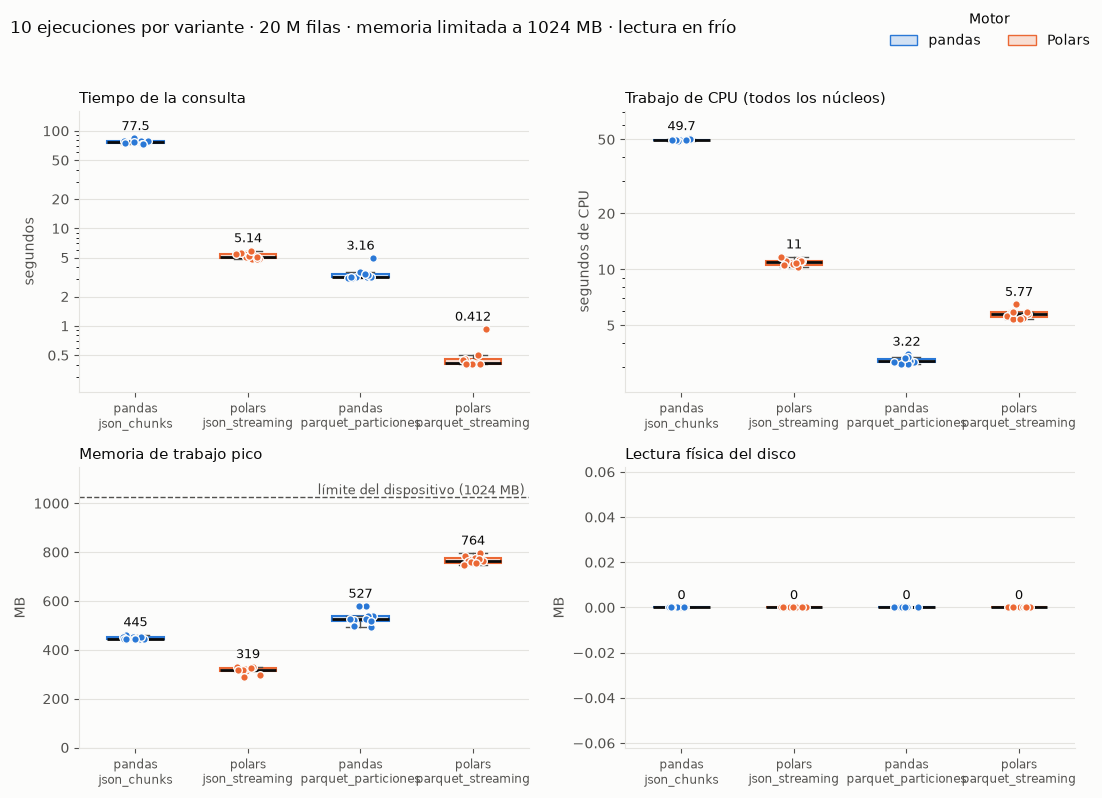

In [26]:
COLOR_MOTOR = {'pandas': '#2a78d6', 'polars': '#eb6834'}
NOMBRE_MOTOR = {'pandas': 'pandas', 'polars': 'Polars'}
FONDO, TEXTO, TEXTO_SECUNDARIO, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
PANELES = [('segundos', 'Tiempo de la consulta', 'segundos'),
           ('cpu_segundos', 'Trabajo de CPU (todos los núcleos)', 'segundos de CPU'),
           ('anon_pico_MB', 'Memoria de trabajo pico', 'MB'),
           ('disco_fisico_MB', 'Lectura física del disco', 'MB')]
etiquetas = [nombre.replace('_', '\n', 1) for nombre in NOMBRES]
colores = [COLOR_MOTOR[nombre.split('_')[0]] for nombre in NOMBRES]
puntos = np.random.default_rng(SEMILLA)

fig, ejes = plt.subplots(2, 2, figsize=(11, 8), facecolor=FONDO)
for ax, (columna, titulo, unidad) in zip(ejes.flat, PANELES):
    datos = [mediciones.filter(pl.col('variante') == v)[columna].to_numpy() for v in NOMBRES]
    ax.set_facecolor(FONDO)
    cajas = ax.boxplot(datos, tick_labels=etiquetas, widths=0.5, patch_artist=True, showfliers=False,
                       medianprops={'color': TEXTO, 'linewidth': 2},
                       whiskerprops={'color': TEXTO_SECUNDARIO}, capprops={'color': TEXTO_SECUNDARIO})
    for posicion, (caja, valores, color) in enumerate(zip(cajas['boxes'], datos, colores), start=1):
        caja.set(facecolor=color + '33', edgecolor=color, linewidth=1.5)
        ax.scatter(posicion + puntos.uniform(-0.12, 0.12, len(valores)), valores, s=30,
                   color=color, edgecolor=FONDO, linewidth=1, zorder=3)
        ax.annotate(f'{np.median(valores):.3g}', (posicion, valores.max()), xytext=(0, 6),
                    textcoords='offset points', ha='center', color=TEXTO, fontsize=9)
    ax.margins(y=0.12)
    medianas_panel = [np.median(valores) for valores in datos]
    if max(medianas_panel) / max(min(medianas_panel), 1e-9) > 10:
        ax.set_yscale('log')
        ax.yaxis.set_major_locator(LogLocator(subs=[1, 2, 5]))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
        ax.yaxis.set_minor_formatter(NullFormatter())
    if columna == 'anon_pico_MB':
        ax.set_ylim(0, MEMORIA_MAX_MB * 1.12)
        ax.axhline(MEMORIA_MAX_MB, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1)
        ax.text(0.99, MEMORIA_MAX_MB, f'límite del dispositivo ({MEMORIA_MAX_MB} MB)',
                transform=ax.get_yaxis_transform(), ha='right', va='bottom',
                color=TEXTO_SECUNDARIO, fontsize=9)
    ax.set_title(titulo, loc='left', color=TEXTO, fontsize=11)
    ax.set_ylabel(unidad, color=TEXTO_SECUNDARIO)
    ax.grid(axis='y', color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']:
        ax.spines[lado].set_color(REJILLA)
    ax.tick_params(colors=TEXTO_SECUNDARIO)
    ax.tick_params(axis='x', labelsize=8.5)
fig.legend(handles=[Patch(facecolor=c + '33', edgecolor=c, label=NOMBRE_MOTOR[m]) for m, c in COLOR_MOTOR.items()],
           title='Motor', frameon=False, labelcolor=TEXTO, loc='upper right', ncols=2)
fig.suptitle(f'{N_EJECUCIONES} ejecuciones por variante · {FILAS / 1e6:.0f} M filas · '
             f'memoria limitada a {MEMORIA_MAX_MB} MB · lectura en frío', x=0.01, ha='left', color=TEXTO)
plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(OUT / 'metricas_benchmark.png', dpi=150, facecolor=FONDO)
plt.show()

## 4L. Test de Friedman y comparaciones post-hoc

Es el mismo procedimiento de `Read_pqrs.ipynb`, ahora en una función, `analizar(mediciones,
columna)`, para aplicarlo a **tiempo**, **memoria** y **CPU** sin repetir código.

**Hipótesis (para cada métrica)**

- **H0:** las cuatro variantes son estadísticamente iguales en esa métrica.
- **H1:** al menos una variante es distinta de las demás.

**Por qué Friedman:** es la alternativa no paramétrica al ANOVA de medidas repetidas. No supone
normalidad y trata cada ejecución como un **bloque**: las cuatro variantes se midieron en la
misma ejecución, en condiciones parecidas de la máquina.

**Cómo funciona**

1. En cada ejecución (fila) se ordenan las variantes: rango 1 = la menor, 4 = la mayor.
2. Se promedia el rango de cada variante en las N ejecuciones: $\bar R_j$.
3. Si H0 fuese cierta, todos los rangos medios estarían cerca de $(k+1)/2 = 2{,}5$.
4. El estadístico mide cuánto se alejan:
   $\chi^2_F = \dfrac{12N}{k(k+1)}\left[\sum_j \bar R_j^2 - \dfrac{k(k+1)^2}{4}\right]$,
   que sigue aproximadamente una $\chi^2$ con $k-1$ grados de libertad. Si $p < \alpha$, se
   rechaza H0.

**Post-hoc:** Friedman dice **si** hay diferencias, no **entre cuáles**. Con k = 4 hay 6 pares,
y cada método controla el aumento de falsos positivos por comparar muchos pares:

- **Nemenyi**, sobre los mismos rangos: $SE = \sqrt{k(k+1)/(6N)}$, $z = |\bar R_i - \bar R_j| / SE$.
  El p-valor sale del **rango estudentizado** (`stats.studentized_range`). Dos variantes
  difieren si sus rangos medios se separan más que $CD = \dfrac{q_\alpha}{\sqrt 2}\, SE$.
- **Wilcoxon de rangos con signo + Holm**: compara las diferencias reales, ejecución a
  ejecución, de cada par. Holm ordena los 6 p-valores de menor a mayor, multiplica el i-ésimo
  por (6 − i + 1) y mantiene la secuencia no decreciente.

**Por qué los dos:** con N = 10, Nemenyi es **conservador**. Si una variante queda siempre
1.ª y otra siempre 2.ª, sus rangos medios difieren en 1, menos que CD ≈ 1,48, y Nemenyi no las
separa. Wilcoxon-Holm sí detecta esa ventaja sistemática. Con N = 10, el p-valor exacto más
pequeño de Wilcoxon es $2/2^{10} \approx 0{,}002$, y tras Holm ≈ 0,012. Si varios pares muestran
ese valor, en todos ellos una variante ganó siempre.

En la función:

- `pivot` deja una fila por ejecución y una columna por variante; `to_numpy()` da la matriz `X` (N × k).
- `rankdata` asigna rangos dentro de cada fila; `friedmanchisquare(*X.T)` recibe una muestra
  por variante. El estadístico también se calcula con la fórmula para comprobarlo; si hubiera
  empates, scipy aplica una corrección y los dos valores diferirían un poco.
- Si dos variantes tienen exactamente los mismos valores, Wilcoxon no tiene diferencias que
  ordenar: se asigna p = 1.
- `mejor` es la variante con menor mediana del par y `razon_medianas` cuántas veces mayor es la
  mediana de la otra.

In [28]:
def holm(p_valores):
    m = len(p_valores)
    ajustados, acumulado = [0.0] * m, 0.0
    for posicion, indice in enumerate(np.argsort(p_valores)):
        acumulado = max(acumulado, min(1.0, (m - posicion) * p_valores[indice]))
        ajustados[indice] = acumulado
    return ajustados

def analizar(tabla, columna):
    ancho = tabla.pivot(on='variante', index='ejecucion', values=columna).sort('ejecucion')
    X = ancho.select(NOMBRES).to_numpy()
    N, k = X.shape
    rangos = np.apply_along_axis(stats.rankdata, 1, X)
    medios = rangos.mean(axis=0)
    chi2_formula = 12 * N / (k * (k + 1)) * (np.sum(medios ** 2) - k * (k + 1) ** 2 / 4)
    estadistico, p_friedman = stats.friedmanchisquare(*X.T)
    SE = np.sqrt(k * (k + 1) / (6 * N))
    CD = stats.studentized_range.ppf(1 - ALFA, k, np.inf) / np.sqrt(2) * SE
    pares = list(itertools.combinations(range(k), 2))
    p_wilcoxon = [1.0 if np.array_equal(X[:, i], X[:, j]) else stats.wilcoxon(X[:, i], X[:, j]).pvalue
                  for i, j in pares]
    filas = []
    for (i, j), p_w in zip(pares, holm(p_wilcoxon)):
        diferencia = abs(medios[i] - medios[j])
        p_n = stats.studentized_range.sf(diferencia / SE * np.sqrt(2), k, np.inf)
        mediana_i, mediana_j = np.median(X[:, i]), np.median(X[:, j])
        filas.append({'variante_a': NOMBRES[i], 'variante_b': NOMBRES[j],
                      'mejor': NOMBRES[i] if mediana_i < mediana_j else NOMBRES[j],
                      'dif_rangos': diferencia,
                      'p_nemenyi': float(p_n), 'nemenyi_signif': bool(p_n < ALFA),
                      'p_wilcoxon_holm': float(p_w), 'wilcoxon_signif': bool(p_w < ALFA),
                      'razon_medianas': max(mediana_i, mediana_j) / min(mediana_i, mediana_j)})
    return {'columna': columna, 'ancho': ancho, 'N': N, 'k': k,
            'rango_medio': dict(zip(NOMBRES, medios)), 'mediana': dict(zip(NOMBRES, np.median(X, axis=0))),
            'chi2': estadistico, 'chi2_formula': chi2_formula, 'p': p_friedman,
            'rechaza_h0': p_friedman < ALFA, 'CD': CD,
            'posthoc': pl.DataFrame(filas).sort('dif_rangos', descending=True)}

### Tiempo

Mostramos la matriz de tiempos (ejecución × variante), los rangos medios, el estadístico de
Friedman (calculado por scipy y por la fórmula) y la tabla post-hoc.

In [29]:
tiempo = analizar(mediciones, 'segundos')
display(tiempo['ancho'])
display(pl.DataFrame({'variante': NOMBRES, 'rango_medio': list(tiempo['rango_medio'].values())}).sort('rango_medio'))
print(f"Friedman: chi² = {tiempo['chi2']:.3f} (fórmula: {tiempo['chi2_formula']:.3f}), "
      f"gl = {tiempo['k'] - 1}, p = {tiempo['p']:.3e}")
print('Se rechaza H0' if tiempo['rechaza_h0'] else 'No se rechaza H0', f'con alfa = {ALFA}')
print(f"Diferencia crítica de Nemenyi: CD = {tiempo['CD']:.3f} rangos (k = {tiempo['k']}, N = {tiempo['N']})")
display(tiempo['posthoc'])

ejecucion,polars_parquet_streaming,pandas_parquet_particiones,pandas_json_chunks,polars_json_streaming
i64,f64,f64,f64,f64
1,0.404958,3.139414,76.85195,5.427187
2,0.92836,3.157553,83.572228,4.801602
3,0.410562,4.968818,77.649791,4.889788
4,0.402379,3.167098,78.687819,4.849105
5,0.41428,3.354391,77.862863,5.101077
6,0.462185,3.094442,79.565869,5.5551
7,0.443838,3.554314,72.839458,5.178816
8,0.408539,3.075468,73.994122,5.444052
9,0.409035,3.155461,74.793414,5.087894


variante,rango_medio
str,f64
"""polars_parquet_streaming""",1.0
"""pandas_parquet_particiones""",2.1
"""polars_json_streaming""",2.9
"""pandas_json_chunks""",4.0


Friedman: chi² = 28.920 (fórmula: 28.920), gl = 3, p = 2.328e-06
Se rechaza H0 con alfa = 0.05
Diferencia crítica de Nemenyi: CD = 1.483 rangos (k = 4, N = 10)


variante_a,variante_b,mejor,dif_rangos,p_nemenyi,nemenyi_signif,p_wilcoxon_holm,wilcoxon_signif,razon_medianas
str,str,str,f64,f64,bool,f64,bool,f64
"""pandas_json_chunks""","""polars_parquet_streaming""","""polars_parquet_streaming""",3.0,0.000001,true,0.011719,true,187.845365
"""pandas_json_chunks""","""pandas_parquet_particiones""","""pandas_parquet_particiones""",1.9,0.005515,true,0.011719,true,24.498226
"""polars_json_streaming""","""polars_parquet_streaming""","""polars_parquet_streaming""",1.9,0.005515,true,0.011719,true,12.462865
"""pandas_json_chunks""","""polars_json_streaming""","""polars_json_streaming""",1.1,0.225741,false,0.011719,true,15.072407
"""pandas_parquet_particiones""","""polars_parquet_streaming""","""polars_parquet_streaming""",1.1,0.225741,false,0.011719,true,7.667713
"""polars_json_streaming""","""pandas_parquet_particiones""","""pandas_parquet_particiones""",0.8,0.508353,false,0.011719,true,1.625369


### Memoria de trabajo y CPU

Aplicamos la misma función al **pico de memoria anónima** y a los **CPU-segundos**. El disco
no pasa por Friedman: la lectura física es casi idéntica en cada corrida, porque depende del
formato y no del azar, así que basta con la descripción de 4K.

In [30]:
memoria = analizar(mediciones, 'anon_pico_MB')
cpu = analizar(mediciones, 'cpu_segundos')
for analisis, titulo in [(memoria, 'Memoria de trabajo pico (MB)'), (cpu, 'CPU-segundos')]:
    print(f"{titulo}: Friedman chi² = {analisis['chi2']:.3f}, p = {analisis['p']:.3e} → "
          + ('se rechaza H0' if analisis['rechaza_h0'] else 'no se rechaza H0'))
    display(analisis['posthoc'])

Memoria de trabajo pico (MB): Friedman chi² = 30.000, p = 1.380e-06 → se rechaza H0


variante_a,variante_b,mejor,dif_rangos,p_nemenyi,nemenyi_signif,p_wilcoxon_holm,wilcoxon_signif,razon_medianas
str,str,str,f64,f64,bool,f64,bool,f64
"""polars_json_streaming""","""polars_parquet_streaming""","""polars_json_streaming""",3.0,0.000001,true,0.011719,true,2.393881
"""pandas_json_chunks""","""polars_parquet_streaming""","""pandas_json_chunks""",2.0,0.002989,true,0.011719,true,1.71767
"""polars_json_streaming""","""pandas_parquet_particiones""","""polars_json_streaming""",2.0,0.002989,true,0.011719,true,1.652721
"""pandas_json_chunks""","""polars_json_streaming""","""polars_json_streaming""",1.0,0.30695,false,0.011719,true,1.393679
"""pandas_json_chunks""","""pandas_parquet_particiones""","""pandas_json_chunks""",1.0,0.30695,false,0.011719,true,1.185869
"""pandas_parquet_particiones""","""polars_parquet_streaming""","""pandas_parquet_particiones""",1.0,0.30695,false,0.011719,true,1.448449


CPU-segundos: Friedman chi² = 30.000, p = 1.380e-06 → se rechaza H0


variante_a,variante_b,mejor,dif_rangos,p_nemenyi,nemenyi_signif,p_wilcoxon_holm,wilcoxon_signif,razon_medianas
str,str,str,f64,f64,bool,f64,bool,f64
"""pandas_json_chunks""","""pandas_parquet_particiones""","""pandas_parquet_particiones""",3.0,0.000001,true,0.011719,true,15.444581
"""pandas_json_chunks""","""polars_parquet_streaming""","""polars_parquet_streaming""",2.0,0.002989,true,0.011719,true,8.610731
"""polars_json_streaming""","""pandas_parquet_particiones""","""pandas_parquet_particiones""",2.0,0.002989,true,0.011719,true,3.40621
"""pandas_json_chunks""","""polars_json_streaming""","""polars_json_streaming""",1.0,0.30695,false,0.011719,true,4.534242
"""polars_json_streaming""","""polars_parquet_streaming""","""polars_parquet_streaming""",1.0,0.30695,false,0.011719,true,1.899046
"""pandas_parquet_particiones""","""polars_parquet_streaming""","""pandas_parquet_particiones""",1.0,0.30695,false,0.011719,true,1.793643


### Conclusión estadística por factor

`conclusion(analisis, que)` redacta, como la sección E7 de `Read_pqrs.ipynb`, la decisión de
Friedman, el ranking por rango medio y frente a qué variantes es significativa la ventaja de la
mejor.

- La **mejor** variante es la de **menor rango medio**; si hay empate, decide la mediana.
- Las variantes que **no** se distinguen de ella según Wilcoxon-Holm forman el **grupo mejor**:
  entre ellas no hay evidencia de diferencia.
- La función devuelve ese grupo para usarlo en la matriz de decisión.

In [31]:
def conclusion(analisis, que, unidad):
    rango, mediana = analisis['rango_medio'], analisis['mediana']
    mejor = min(NOMBRES, key=lambda v: (rango[v], mediana[v]))
    print(f"{que} · Friedman: chi² = {analisis['chi2']:.2f}, p = {analisis['p']:.3e} → "
          + ('se rechaza H0.' if analisis['rechaza_h0'] else 'no se rechaza H0.'))
    print('  Ranking por rango medio:',
          ', '.join(f'{v} ({r:.2f})' for v, r in sorted(rango.items(), key=lambda par: par[1])))
    frente = analisis['posthoc'].filter((pl.col('variante_a') == mejor) | (pl.col('variante_b') == mejor))
    for fila in frente.iter_rows(named=True):
        otra = fila['variante_b'] if fila['variante_a'] == mejor else fila['variante_a']
        print(f"  {mejor} vs {otra}: {mediana[mejor]:.3g} frente a {mediana[otra]:.3g} {unidad} "
              f"({fila['razon_medianas']:.1f}×) | Nemenyi p = {fila['p_nemenyi']:.4f} | "
              f"Wilcoxon-Holm p = {fila['p_wilcoxon_holm']:.4f}")
    no_separadas = [fila['variante_b'] if fila['variante_a'] == mejor else fila['variante_a']
                    for fila in frente.iter_rows(named=True)
                    if not fila['wilcoxon_signif'] or fila['mejor'] != mejor]
    if not analisis['rechaza_h0']:
        print('  Conclusión: no hay evidencia de diferencias entre las variantes.\n')
        return list(NOMBRES)
    if not no_separadas:
        print(f'  Conclusión: {mejor} es la mejor y su ventaja es significativa frente a todas '
              f'(Wilcoxon-Holm, alfa = {ALFA}).\n')
    else:
        print(f'  Conclusión: grupo mejor = {", ".join([mejor] + no_separadas)}; entre ellas no hay '
              f'diferencia significativa (Wilcoxon-Holm, alfa = {ALFA}).\n')
    return [mejor] + no_separadas

grupo_mejor = {'tiempo': conclusion(tiempo, 'TIEMPO', 's'),
               'memoria': conclusion(memoria, 'MEMORIA DE TRABAJO', 'MB'),
               'cpu': conclusion(cpu, 'CPU', 's de CPU')}

TIEMPO · Friedman: chi² = 28.92, p = 2.328e-06 → se rechaza H0.
  Ranking por rango medio: polars_parquet_streaming (1.00), pandas_parquet_particiones (2.10), polars_json_streaming (2.90), pandas_json_chunks (4.00)
  polars_parquet_streaming vs pandas_json_chunks: 0.412 frente a 77.5 s (187.8×) | Nemenyi p = 0.0000 | Wilcoxon-Holm p = 0.0117
  polars_parquet_streaming vs polars_json_streaming: 0.412 frente a 5.14 s (12.5×) | Nemenyi p = 0.0055 | Wilcoxon-Holm p = 0.0117
  polars_parquet_streaming vs pandas_parquet_particiones: 0.412 frente a 3.16 s (7.7×) | Nemenyi p = 0.2257 | Wilcoxon-Holm p = 0.0117
  Conclusión: polars_parquet_streaming es la mejor y su ventaja es significativa frente a todas (Wilcoxon-Holm, alfa = 0.05).

MEMORIA DE TRABAJO · Friedman: chi² = 30.00, p = 1.380e-06 → se rechaza H0.
  Ranking por rango medio: polars_json_streaming (1.00), pandas_json_chunks (2.00), pandas_parquet_particiones (3.00), polars_parquet_streaming (4.00)
  polars_json_streaming vs polars_pa

## 4M. Prueba nueva: ¿qué pasa si el volumen se duplica?

El enunciado advierte que el volumen podría duplicarse. Repetimos las cuatro variantes con
`volumen=2`: cada motor procesa **40 millones de filas**, porque la lista de archivos se lee dos
veces. Mantenemos el mismo límite de memoria y la lectura en frío.

- `N_DOBLE = 3` repeticiones por variante en orden aleatorio, como en el protocolo corto del
  cuaderno 04, para no alargar la clase. Esta prueba es **descriptiva**: sin calentamiento ni
  Friedman.
- Cada resultado se verifica contra `esperada(2)`: el doble de observaciones y de lluvia total,
  con las mismas medias.
- Las **razones 2×/1×** comparan medianas. Se espera que tiempo, CPU y disco se acerquen a 2
  (crecimiento proporcional) y que la memoria quede cerca de 1, porque un buen diseño por
  partes **no** debería necesitar más memoria con más datos.

In [32]:
generador_doble = random.Random(SEMILLA + 1)
filas_doble = []
for repeticion in range(1, N_DOBLE + 1):
    exigir_exclusividad()
    orden = list(NOMBRES)
    generador_doble.shuffle(orden)
    for nombre in orden:
        medicion, resultado = ejecutar_acotado(nombre, volumen=2)
        assert not medicion['oom'], f'{nombre} superó el límite de memoria con el doble de datos'
        verificar(resultado, volumen=2)
        filas_doble.append(medicion | {'ejecucion': repeticion})
    print(f'repetición {repeticion}: {" → ".join(orden)}')

doble = derivar(pl.DataFrame(filas_doble))
doble.write_csv(OUT / 'mediciones_doble.csv')

FACTORES_2X = ['segundos', 'cpu_segundos', 'anon_pico_MB', 'disco_fisico_MB']
escalamiento = (
    mediciones.group_by('variante').agg(pl.col(FACTORES_2X).median())
    .join(doble.group_by('variante').agg(pl.col(FACTORES_2X).median()), on='variante', suffix='_2x')
    .with_columns([(pl.col(f'{c}_2x') / pl.col(c)).alias(f'razon_{c}') for c in FACTORES_2X])
    .with_columns(margen_2x_MB=MEMORIA_MAX_MB - pl.col('anon_pico_MB_2x'))
    .sort('segundos')
)
with pl.Config(float_precision=2, tbl_cols=-1):
    display(escalamiento.select('variante', 'segundos', 'segundos_2x', 'razon_segundos',
                                'anon_pico_MB', 'anon_pico_MB_2x', 'razon_anon_pico_MB', 'margen_2x_MB',
                                'razon_cpu_segundos', 'razon_disco_fisico_MB'))

repetición 1: pandas_parquet_particiones → polars_parquet_streaming → polars_json_streaming → pandas_json_chunks
repetición 2: pandas_parquet_particiones → pandas_json_chunks → polars_json_streaming → polars_parquet_streaming
repetición 3: pandas_json_chunks → polars_json_streaming → pandas_parquet_particiones → polars_parquet_streaming


variante,segundos,segundos_2x,razon_segundos,anon_pico_MB,anon_pico_MB_2x,razon_anon_pico_MB,margen_2x_MB,razon_cpu_segundos,razon_disco_fisico_MB
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""polars_parquet_streaming""",0.41,0.80,1.94,763.51,1016.80,1.33,7.20,2.20,NaN
"""pandas_parquet_particiones""",3.16,6.55,2.07,527.12,647.61,1.23,376.39,2.00,NaN
"""polars_json_streaming""",5.14,9.86,1.92,318.94,498.14,1.56,525.86,1.99,NaN
"""pandas_json_chunks""",77.47,162.46,2.10,444.50,444.25,1.00,579.75,1.99,NaN


# Paso 5 · Interpretar y decidir

## 5A. Matriz de decisión con varios criterios

Reunimos en una tabla **todos** los factores medidos (medianas de las 10 ejecuciones a 1× y
de la prueba 2×) y añadimos el que no se mide con un cronómetro: el **costo de aprendizaje**.

| Criterio | Mejor si es | Peso de ejemplo | Por qué |
|---|---|---|---|
| `segundos` | menor | 0,20 | latencia del proceso semanal |
| `cpu_segundos` | menor | 0,10 | trabajo total; importa si el equipo es compartido |
| `anon_pico_MB` | menor | 0,15 | memoria de trabajo con el volumen actual |
| `margen_2x_MB` | mayor | 0,15 | holgura frente al límite cuando el volumen se duplique |
| `MB_a_decodificar` | menor | 0,10 | bytes que el formato obliga a procesar |
| `costo_aprendizaje` | menor | 0,30 | el equipo conoce pandas (1) y no Polars (2) |

- Cada criterio se convierte en un **rango** (1 = mejor; si hay empate, ambos reciben el menor)
  y el **puntaje** es la suma ponderada de rangos: **menor es mejor**.
- Los pesos son un **juicio del equipo**, no un resultado del experimento. Aquí pesa mucho el
  aprendizaje porque el enunciado lo destaca; cambie `PESOS` y observe si cambia la decisión.
- Los rangos ocultan magnitudes (43 s y 1 s difieren en un solo puesto). Por eso la matriz
  muestra también los valores y la decisión final se argumenta en texto.

In [33]:
COSTO_APRENDIZAJE = {'pandas': 1, 'polars': 2}
PESOS = {'segundos': 0.20, 'cpu_segundos': 0.10, 'anon_pico_MB': 0.15,
         'margen_2x_MB': 0.15, 'MB_a_decodificar': 0.10, 'costo_aprendizaje': 0.30}
MAYOR_ES_MEJOR = {'margen_2x_MB'}
assert abs(sum(PESOS.values()) - 1) < 1e-9

matriz = (
    medianas.select('variante', 'segundos', 'cpu_segundos', 'nucleos_promedio', 'anon_pico_MB', 'disco_fisico_MB')
    .join(escalamiento.select('variante', 'margen_2x_MB', 'razon_segundos'), on='variante')
    .with_columns(motor=pl.col('variante').str.split('_').list.first(),
                  MB_a_decodificar=pl.when(pl.col('variante').str.contains('json'))
                                     .then(MB_NDJSON).otherwise(MB_PARQUET_CONSULTA))
    .with_columns(costo_aprendizaje=pl.col('motor').replace_strict(COSTO_APRENDIZAJE))
)
rangos = matriz.select('variante', *[pl.col(c).rank('min', descending=c in MAYOR_ES_MEJOR).alias(f'rango_{c}')
                                     for c in PESOS])
decision = (matriz.join(rangos, on='variante')
            .with_columns(puntaje=pl.sum_horizontal([pl.col(f'rango_{c}') * peso for c, peso in PESOS.items()]))
            .sort('puntaje'))
decision.write_csv(OUT / 'matriz_decision.csv')
with pl.Config(float_precision=2, tbl_cols=-1):
    display(decision.select('variante', 'segundos', 'cpu_segundos', 'nucleos_promedio', 'anon_pico_MB',
                            'margen_2x_MB', 'disco_fisico_MB', 'MB_a_decodificar', 'costo_aprendizaje'))
    display(decision.select('variante', *[f'rango_{c}' for c in PESOS], 'puntaje'))

variante,segundos,cpu_segundos,nucleos_promedio,anon_pico_MB,margen_2x_MB,disco_fisico_MB,MB_a_decodificar,costo_aprendizaje
str,f64,f64,f64,f64,f64,f64,f64,i64
"""pandas_parquet_particiones""",3.16,3.22,1.00,527.12,376.39,0.00,15.72,1
"""pandas_json_chunks""",77.47,49.68,0.64,444.50,579.75,0.00,1992.40,1
"""polars_json_streaming""",5.14,10.96,2.05,318.94,525.86,0.00,1992.40,2
"""polars_parquet_streaming""",0.41,5.77,13.35,763.51,7.20,0.00,15.72,2


variante,rango_segundos,rango_cpu_segundos,rango_anon_pico_MB,rango_margen_2x_MB,rango_MB_a_decodificar,rango_costo_aprendizaje,puntaje
str,u32,u32,u32,u32,u32,u32,f64
"""pandas_parquet_particiones""",2,1,3,3,1,1,1.80
"""pandas_json_chunks""",4,4,2,1,3,1,2.25
"""polars_json_streaming""",3,3,1,2,3,3,2.55
"""polars_parquet_streaming""",1,2,4,4,1,3,2.60


## 5B. Indicadores para el informe

La celda reúne los números que cita la respuesta del equipo y los guarda, junto con la
configuración del experimento, en `indicadores_ejercicio.json` y `configuracion_benchmark.json`.

In [34]:
m = dict(zip(medianas['variante'], medianas.iter_rows(named=True)))
indicadores = {
    'filas_1x': FILAS, 'MB_ndjson': round(MB_NDJSON), 'MB_parquet': round(MB_PARQUET, 1),
    'memoria_max_MB': MEMORIA_MAX_MB, 'limite_real': LIMITE_REAL,
    'pandas_completo_oom': completo['oom'],
    'equivalencia_confirmada': equivalencia['equivalentes'],
    **{f'segundos_{v}': round(m[v]['segundos'], 3) for v in NOMBRES},
    **{f'cpu_segundos_{v}': round(m[v]['cpu_segundos'], 2) for v in NOMBRES},
    **{f'nucleos_{v}': round(m[v]['nucleos_promedio'], 1) for v in NOMBRES},
    **{f'memoria_MB_{v}': round(m[v]['anon_pico_MB']) for v in NOMBRES},
    **{f'disco_fisico_MB_{v}': round(m[v]['disco_fisico_MB'], 1) for v in NOMBRES},
    'aceleracion_json_polars_vs_pandas': m['pandas_json_chunks']['segundos'] / m['polars_json_streaming']['segundos'],
    'aceleracion_parquet_polars_vs_pandas': m['pandas_parquet_particiones']['segundos'] / m['polars_parquet_streaming']['segundos'],
    'aceleracion_pandas_parquet_vs_json': m['pandas_json_chunks']['segundos'] / m['pandas_parquet_particiones']['segundos'],
    'grupo_mejor': grupo_mejor,
    'mejor_puntaje': decision['variante'][0],
}
(OUT / 'indicadores_ejercicio.json').write_text(json.dumps(indicadores, indent=2, ensure_ascii=False), encoding='utf-8')
configuracion_equipo.update({
    'fin_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'memoria_max_MB': MEMORIA_MAX_MB, 'limite_real': LIMITE_REAL, 'lectura_en_frio': LECTURA_EN_FRIO,
    'chunk_filas': CHUNK_FILAS, 'replicas': REPLICAS, 'filas': FILAS,
    'calentamientos': 1, 'ejecuciones_por_variante': N_EJECUCIONES, 'repeticiones_2x': N_DOBLE,
    'frontera_temporal': 'lectura + selección + agrupación + combinación + materialización',
    'metodo_memoria': 'pico de RssAnon muestreado cada 10 ms dentro del proceso medido',
    'metodo_disco': 'rbytes de io.stat del cgroup del proceso medido',
})
(OUT / 'configuracion_benchmark.json').write_text(json.dumps(configuracion_equipo, indent=2, ensure_ascii=False), encoding='utf-8')
display(pl.DataFrame({'indicador': list(indicadores), 'valor': [str(v) for v in indicadores.values()]}))

indicador,valor
str,str
"""filas_1x""","""20034432"""
"""MB_ndjson""","""1992"""
"""MB_parquet""","""20.3"""
"""memoria_max_MB""","""1024"""
"""limite_real""","""True"""
"""pandas_completo_oom""","""True"""
"""equivalencia_confirmada""","""True"""
"""segundos_pandas_json_chunks""","""77.471"""
"""segundos_polars_json_streaming""","""5.14"""


## 5C. Respuesta del equipo

*Las cifras corresponden a la ejecución guardada en este cuaderno (24 de octubre de 2026, 8 núcleos, NVMe, límite de 1.024 MB). Si se vuelve a ejecutar, cambiarán un poco; las celdas 4L a 5B muestran siempre las cifras vigentes.*

**Decisión que debemos tomar.** Para el resumen departamental semanal: mantener pandas, migrar a Polars o adoptarlo de forma gradual, en un equipo cuya memoria es menor que los datos y con un volumen que puede duplicarse.

**Hipótesis inicial.** Polars en *streaming* sería más rápido, haría menos trabajo de CPU y usaría menos memoria que pandas por trozos. Parquet ayudaría a ambos motores. Resultado:

- **Tiempo y CPU: se confirma.** Polars es más rápido y hace menos trabajo de CPU, con diferencias significativas.
- **Memoria: se refuta en parte.** Polars sobre JSON fue la variante con menos memoria (346 MB). En cambio, Polars sobre Parquet (482 MB) usó más que pandas sobre JSON (453 MB).

**Resultado equivalente que validamos.**

- Las cuatro variantes reproducen la tabla esperada calculada a mano: 165 grupos (33 departamentos × 5 semanas) y 20.034.432 filas. La tolerancia relativa fue de 10⁻⁹, y los conteos, mínimos y máximos coincidieron exactamente.
- Con el doble de datos, las cuatro reproducen la tabla esperada con `volumen=2`.
- `pandas_completo`, que lee el NDJSON de una vez, **murió por falta de memoria en 0,5 s**: en este dispositivo leer por partes no es opcional.

**Etapa o recurso que explica la diferencia.**

- **Decodificar texto, es decir, CPU.** pandas sobre JSON gastó 42,6 s de CPU en 42,9 s de reloj: un núcleo ocupado todo el tiempo.
- **El disco no es el cuello de botella.** Solo leyó 63 MB físicos, porque btrfs comprime el NDJSON replicado unas 30 veces, es decir, 1,5 MB/s.
- **Lo confirma el cambio de formato.** Con el mismo motor, pasar a Parquet bajó pandas de 42,9 s a 1,78 s (24×), porque casi no queda texto que convertir.
- **Polars gana por dos razones.** Hace menos trabajo (5,5 frente a 42,6 s de CPU en JSON) y además lo reparte en unos 5 núcleos.
- La predicción del paso 2 (CPU, no disco) se cumple.

**Lo que dicen los cuatro factores** (medianas de 10 ejecuciones; Friedman p < 10⁻⁵ en tiempo, memoria y CPU; Wilcoxon-Holm significativo en los 6 pares de cada factor; Nemenyi, más conservador, no separa los pares de rangos contiguos):

| | pandas JSON | Polars JSON | pandas Parquet | Polars Parquet |
|---|---|---|---|---|
| Tiempo | 42,9 s | 1,12 s | 1,78 s | **0,16 s** |
| CPU (núcleos) | 42,6 s (1,0) | 5,5 s (5,0) | 2,0 s (1,1) | **0,84 s** (5,4) |
| Memoria de trabajo | 453 MB | **346 MB** | 519 MB | 482 MB |
| Memoria con 2× | **453 MB** (plana) | 528 MB | 670 MB | 612 MB |
| Tiempo con 2× | 2,03× | 2,11× | 2,01× | 1,97× |
| Disco físico | 63 MB | 67 MB | 2,5 MB | 2,3 MB |

**Recomendación para la entidad: adopción gradual.**

**Etapa 1, ya: cambiar el formato, no el motor.**

- El tiempo **no** es la razón principal. Un proceso semanal de 43 s (87 s con el doble de datos) es aceptable.
- Las razones de fondo son la memoria y el riesgo:
  - pandas solo cabe si lee por trozos y agrega en dos fases. Ese código es fácil de equivocar: promediar medias, o perder el cero de `05` sin `dtype`.
  - Guardar los datos semanales en Parquet particionado por departamento permite que pandas lea una partición a la vez. Con eso hace 21 veces menos trabajo de CPU (2,0 s frente a 42,6 s) y le quedan 354 MB de margen con el doble de datos.
- El costo de aprendizaje es bajo: es el mismo pandas que el equipo ya usa.

**Etapa 2, piloto: Polars para el resumen.**

- La consulta completa es una función de unas 15 líneas (`consulta_polars`). Polars hace el *streaming* y la agregación en dos fases que en pandas hubo que programar a mano.
- En Parquet es 11× más rápido que pandas y hace 2,4× menos trabajo de CPU.
- Primero conviene ejecutarlo varias semanas **en paralelo** con pandas y comparar con `assert_frame_equal`, como en 4I. Solo después se reemplaza.
- La conversión a Parquet también se puede hacer con Polars (`sink_parquet` en *streaming*, alrededor de 1 s en nuestras pruebas): es una primera tarea pequeña y aislada para aprender la herramienta.

**Por qué no basta el tiempo más bajo.**

- La matriz de decisión (5A) deja las cuatro variantes muy cerca (2,20 a 2,40) cuando el aprendizaje pesa 0,30.
- Polars Parquet gana en tiempo, CPU y bytes. pandas JSON gana en aprendizaje y en margen de memoria con 2×.
- Con otros pesos el orden cambia; por eso la recomendación se argumenta con todos los factores y no solo con el puntaje.

**Límite principal de esta evidencia.**

- **Los datos son una réplica.** Hay 31 valores distintos por columna, así que Parquet comprime de forma exagerada: 98 veces, cuando con datos reales sería unas pocas. btrfs también comprime el NDJSON. Con datos reales, el disco y Parquet pesarán más.
- **Un solo equipo.** Son 8 núcleos y un NVMe, y el límite de 1 GB es un modelo a escala de 8 GB: no es un equipo de 8 GB real. La ventaja de Polars depende en parte del paralelismo.
- **La memoria no fue plana con 2×** en tres de las cuatro variantes (+27 % a +53 %). La causa probable es memoria que el proceso retiene entre lotes o particiones; no la verificamos.
- **La prueba 2× tiene solo 3 repeticiones** y es descriptiva.

**Próxima prueba antes de adoptar o escalar.**

1. Repetir con un mes real de NASA POWER para varios puntos, o con los PQRS, sin réplica.
2. Medir el volumen 4× y ver si la memoria se estabiliza o sigue creciendo.
3. Fijar `POLARS_MAX_THREADS` en 2 y 4 para simular un equipo más modesto.
4. Medir en el equipo real de 8 GB de la entidad.

## Para practicar

1. Cambiar `CHUNK_FILAS` a 50.000 y a 1.000.000. ¿Qué pasa con la memoria y el tiempo de
   `pandas_json_chunks`? ¿Hay un tamaño que supere el límite?
2. Bajar `MEMORIA_MAX_MB` a 512. ¿Qué variantes siguen cabiendo?
3. Probar `volumen=4` en la prueba de escalamiento. ¿La memoria sigue plana?
4. `LECTURA_EN_FRIO = False`: con la caché caliente, ¿cuánto del tiempo era disco?
5. Ejecutar con `POLARS_MAX_THREADS=1` (variable de entorno del subproceso) para separar la
   ventaja del **motor** de la ventaja del **paralelismo**. Compare los CPU-segundos.
6. Cambiar `PESOS` en 5A. ¿Con qué pesos cambiaría la recomendación?